<a href="https://colab.research.google.com/github/Melonangie/Galaxy-Vision/blob/main/FEatures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Marco teórico: ¿qué es la morfología de una galaxia?

### 1.1 Secuencia de Hubble y sistema de de Vaucouleurs
* **Hubble (1926, 1936)** propuso el "diapasón": elípticas (E0–E7), lenticulares (S0) y espirales normales (S) o barradas (SB),
  de Sa a Sc. Sandage (1961) lo refinó.
* **de Vaucouleurs (1959)** creó un sistema 3D:
  * **estadio** (E → S0 → Sa … Sm → Im);
  * **familia** (SA sin barra, SAB barra débil, SB barra fuerte);
  * **variedad** (anillos r / espirales s).
  El estadio se codifica con el índice **T-type** (RC3; de Vaucouleurs et al. 1991).
* En el catálogo, `Type` guarda la clasificación completa (p. ej. `SABbc`) y `Ttype` solo el estadio.

| T | −5 | −2 | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11* |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Tipo | E | S0 | S0a | Sa | Sab | Sb | Sbc | Sc | Scd | Sd | Sdm | Sm | Im | S sin estadio / mergers |
| B/T aprox.† | ~1 | ~0.6 | ~0.5 | ~0.4 | ~0.3 | ~0.25 | ~0.15 | ~0.1 | ~0.05 | ~0 | ~0 | ~0 | 0 | – |

\*T = 11 es propio de este catálogo y **no es ordinal**.
†Cociente bulbo/total típico (Simien & de Vaucouleurs 1986), con mucha dispersión.

### 1.2 Criterios de clasificación
El estadio combina tres criterios **visuales** (Sandage 2005; Buta 2013):
1. Importancia del bulbo.
2. Qué tan enrollados están los brazos.
3. Resolución de los brazos en nudos y regiones H II.

Ninguno es espectroscópico. El espectro predice la morfología **solo en la medida en que morfología e historia de formación
estelar están ligadas**.

### 1.3 ¿Por qué la morfología se refleja en el espectro?
(Roberts & Haynes 1994; Kennicutt 1998; Blanton & Moustakas 2009)

| Propiedad | E/S0 | Sa–Sbc | Sc–Im | Traza espectral |
|---|---|---|---|---|
| Edad estelar | > 5 Gyr | bulbo viejo + disco joven | < 1–3 Gyr (en luz) | D4000, Hδ_A, edad STARLIGHT |
| Formación estelar (sSFR) | ≈ 0 | intermedia | alta | EW(Hα), EW([OII]) |
| Gas y polvo | poco | intermedio | mucho gas | emisión, A_V, Hα/Hβ |
| Metalicidad / [α/Fe] | alta / alto | alta | baja | Mg b, ⟨Fe⟩, [MgFe]′, N2 |
| Masa y Σ* | altas | intermedias | bajas | LogMass, σ, Σ* |
| Soporte dinámico | dispersión | mixto | rotación | σ estelar |
| Ionización | pasiva / LINER "retirada" | compuesta | H II | BPT, WHAN |

* **Bimodalidad:** existen una secuencia roja y una nube azul (Strateva et al. 2001; Baldry et al. 2004). La transición ocurre
  en Σ* ≈ 3×10⁸ M⊙ kpc⁻² (Kauffmann et al. 2003b).
* **Morfología ≠ color:** hay espirales rojas (Masters et al. 2010) y elípticas azules (Schawinski et al. 2009). Además, las
  relaciones morfología–densidad (Dressler 1980) y color–densidad son en parte independientes (Bamford et al. 2009).
  → **El espectro nunca reproducirá la morfología al 100 %.**
* **Quenching morfológico:** un bulbo masivo estabiliza el gas (Martig et al. 2009). Las tempranas y las tardías cruzan el
  valle verde por caminos distintos (Schawinski et al. 2014).
* **S0 vs E:** las S0 forman una secuencia paralela a las espirales (van den Bergh 1976; Cappellari et al. 2011;
  Kormendy & Bender 2012). Espectralmente se parecen a las E; se separan mejor por estructura y cinemática
  (Emsellem et al. 2011).
* **dSph y BCD** siguen otras relaciones de escala (Kormendy 1985; Kormendy et al. 2009).

### 1.4 Incertidumbre de la etiqueta
Distintos expertos difieren en **σ ≈ 1.8 T** (Naim et al. 1995; Lahav et al. 1995). Separar tipos vecinos tiene un **techo**.

### 1.5 MaNGA y el catálogo
* MaNGA (Bundy et al. 2015; Drory et al. 2015; Law et al. 2016; DR17: Abdurro'uf et al. 2022) observó ~10 000 galaxias con
  z ≈ 0.01–0.15.
* La muestra es plana en masa (Wake et al. 2017), así que **z y M* están correlacionados por diseño**.
* `morfologia.fits` es muy probablemente el VAC de morfología visual (Vázquez-Mata et al. 2022). La otra opción es
  Domínguez Sánchez et al. (2022).

In [1]:
!pip install -q astroML imbalanced-learn

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

# --- Astronomía ---
from astropy.table import Table                       # lee FITS (también .fits.gz)
from astropy import units as u
from astropy.constants import c
from astropy.coordinates import SkyCoord              # coordenadas y cruces por posición
from astropy.cosmology import Planck18 as cosmo       # distancias (flujo -> luminosidad, ″ -> kpc)
from astropy.modeling import models, fitting          # gaussianas para las líneas de emisión
from astropy.visualization import hist as hist_astro  # histogramas con bins de Knuth
from astropy.utils.data import download_file
from astroML.stats import sigmaG                      # dispersión robusta σ_G = 0.7413·IQR

# --- Estadística ---
from scipy.integrate import trapezoid
from scipy.stats import kruskal, spearmanr
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform

# --- Aprendizaje automático ---
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score, cohen_kappa_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline                # Pipeline que admite SMOTE (solo actúa al entrenar)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
SEMILLA = 42   # una sola semilla para que todo sea reproducible

In [3]:
from google.colab import drive
drive.mount('/content/drive')

!cp "/content/drive/MyDrive/Proyecto_morfologia/data/morfologia.fits" /content/
!cp "/content/drive/MyDrive/Proyecto_morfologia/data/MPL-11.zip" /content/
!cp "/content/drive/MyDrive/Proyecto_morfologia/data/FoV-OUT.zip" /content/

!unzip -o -q /content/MPL-11.zip -d /content/fits
!unzip -o -q /content/FoV-OUT.zip -d /content/out

!df -h /content

!ls /content
!ls /content/fits/MPL-11 | wc -l
!ls /content/out/FoV-OUT | wc -l

Mounted at /content/drive
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  5.9G  102G   6% /
drive  fits  FoV-OUT.zip  morfologia.fits  MPL-11.zip  out  sample_data
10243
10243


In [10]:
RUTA_FITS = '/content/fits/MPL-11'      # un espectro 1D por galaxia
RUTA_OUT  = '/content/out/FoV-OUT'      # salidas de STARLIGHT (.out o -out.txt)
RUTA_MORF = '/content/morfologia.fits'  # catálogo morfológico
RUTA_RES  = '/content/drive/MyDrive/Proyecto_morfologia/features_results'   # tablas, figuras y caché
os.makedirs(RUTA_RES, exist_ok=True)

def nombre_galaxia(ruta):
    """'.../manga-10001-12701-1D.fits.gz' -> 'manga-10001-12701'. El plate-ifu es la clave común."""
    return os.path.basename(ruta).split('-1D')[0]

fits_files = sorted(glob.glob(os.path.join(RUTA_FITS, '*.fits*')))
out_files  = sorted(glob.glob(os.path.join(RUTA_OUT, '*out*')))
# Diccionario nombre -> .out. Así evitamos un glob por galaxia, que sería lento con 10 000 archivos.
outs = {nombre_galaxia(p): p for p in out_files}
print(len(fits_files), 'espectros |', len(out_files), 'salidas STARLIGHT')

10243 espectros | 10243 salidas STARLIGHT


In [4]:
C_KMS = c.to(u.km / u.s).value

def aire_a_vacio(l_aire):
    """λ aire -> λ vacío (Ciddor 1996, versión VALD/SDSS). Å."""
    l = np.asarray(l_aire, dtype=float)
    s2 = (1e4 / l) ** 2
    n = 1 + 8.336624212083e-5 + 2.408926869968e-2 / (130.1065924522 - s2) + 1.599740894897e-4 / (38.92568793293 - s2)
    return l * n

V_AIRE_VACIO = C_KMS * (aire_a_vacio(5000.0) / 5000.0 - 1)   # ≈ 83 km/s
print(f'Desplazamiento aire→vacío ≈ {V_AIRE_VACIO:.1f} km/s')

# Líneas de emisión en VACÍO (iguales a las del DAP de MaNGA). Las cercanas se ajustan juntas.
LINEAS_EMISION = {
    'OII':     [('OII_3726', 3727.09), ('OII_3729', 3729.88)],
    'NeIII':   [('NeIII_3869', 3869.86)],
    'Hd':      [('Hd_4102', 4102.89)],
    'Hg_OIII': [('Hg_4341', 4341.69), ('OIII_4363', 4364.44)],
    'Hb':      [('Hb_4861', 4862.69)],
    'OIII':    [('OIII_4959', 4960.30), ('OIII_5007', 5008.24)],
    'HeI':     [('HeI_5876', 5877.25)],
    'OI':      [('OI_6300', 6302.05)],
    'Ha_NII':  [('NII_6548', 6549.86), ('Ha_6563', 6564.61), ('NII_6584', 6585.27)],
    'SII':     [('SII_6717', 6718.29), ('SII_6731', 6732.67)],
    'ArIII':   [('ArIII_7136', 7137.76)],
}

# Índices: (banda central, pseudo-continuo azul, pseudo-continuo rojo), en AIRE
INDICES_AIRE = {
    'CaII_K':  ((3923.7, 3943.7), (3903.0, 3923.0), (3943.7, 3953.0)),
    'HdA':     ((4083.500, 4122.250), (4041.600, 4079.750), (4128.500, 4161.000)),   # Worthey & Ottaviani 1997
    'G4300':   ((4281.375, 4316.375), (4266.375, 4282.625), (4318.875, 4335.125)),   # Worthey et al. 1994
    'HgA':     ((4319.750, 4363.500), (4283.500, 4319.750), (4367.250, 4419.750)),   # Worthey & Ottaviani 1997
    'Hb_Lick': ((4847.875, 4876.625), (4827.875, 4847.875), (4876.625, 4891.625)),   # Trager et al. 1998
    'Mgb':     ((5160.125, 5192.625), (5142.625, 5161.375), (5191.375, 5206.375)),
    'Fe5270':  ((5245.650, 5285.650), (5233.150, 5248.150), (5285.650, 5318.150)),
    'Fe5335':  ((5312.125, 5352.125), (5304.625, 5315.875), (5353.375, 5363.375)),
    'NaD':     ((5876.875, 5909.375), (5860.625, 5875.625), (5922.125, 5948.125)),
    'CaT1':    ((8483.0, 8513.0), (8447.5, 8462.5), (8842.5, 8857.5)),               # Díaz et al. 1989
    'CaT2':    ((8527.0, 8557.0), (8447.5, 8462.5), (8842.5, 8857.5)),
    'CaT3':    ((8647.0, 8677.0), (8447.5, 8462.5), (8842.5, 8857.5)),
}
INDICES = {k: tuple(tuple(aire_a_vacio(b)) for b in v) for k, v in INDICES_AIRE.items()}
D4000_AZUL, D4000_ROJO = aire_a_vacio((3850, 3950)), aire_a_vacio((4000, 4100))   # Balogh et al. 1999

# Líneas de cielo y bandas telúricas (marco OBSERVADO, vacío). Se enmascaran para el PCA y el color.
CIELO_OBS = [(5574, 5584), (5886, 5900), (6296, 6308), (6360, 6370), (6865, 6930), (7590, 7700)]

# Rejilla común en reposo (el espectro observado empieza en 3622 Å)
GRID = np.arange(3650, 8900, 2.0)

NOMBRE_TTYPE = {-5: 'E', -2: 'S0', 0: 'S0a', 1: 'Sa', 2: 'Sab', 3: 'Sb', 4: 'Sbc', 5: 'Sc',
                6: 'Scd', 7: 'Sd', 8: 'Sdm', 9: 'Sm', 10: 'Im', 11: 'S?'}
ORDEN_TTYPE = sorted(NOMBRE_TTYPE)
COLOR_TTYPE = dict(zip(ORDEN_TTYPE, plt.cm.turbo_r(np.linspace(0.02, 0.98, len(ORDEN_TTYPE)))))

Desplazamiento aire→vacío ≈ 83.6 km/s


In [5]:
def leer_tabla_espectro(ruta):
    """Lee un espectro 1D (.fits, .fits.gz o .csv) en el marco OBSERVADO. Columnas en mayúsculas."""
    tabla = pd.read_csv(ruta) if ruta.endswith('.csv') else Table.read(ruta, hdu=1).to_pandas()
    tabla.columns = [col.upper() for col in tabla.columns]     # FLUX_FoV -> FLUX_FOV
    return tabla

def der_snr(flux):
    """S/N sin usar errores (Stoehr et al. 2008)."""
    f = flux[np.isfinite(flux) & (flux != 0)]
    if len(f) < 10:
        return np.nan
    ruido = 0.6052697 * np.median(np.abs(2 * f[2:-2] - f[:-4] - f[4:]))
    return np.median(f) / ruido if ruido > 0 else np.nan

def calidad_espectro(tabla):
    """Métricas de calidad de un espectro (marco observado)."""
    w, f, e = tabla['WAVE'].values, tabla['FLUX_FOV'].values, tabla['ERROR_FOV'].values
    paso = np.diff(w)
    return {'n_pix': len(w), 'lam_min': w.min(), 'lam_max': w.max(),
            'paso_min': paso.min(), 'paso_max': paso.max(),     # paso_max > paso_min => hay huecos
            'n_cero': int((f == 0).sum()),                      # píxeles sin datos (bordes)
            'n_neg': int((f < 0).sum()),                        # flujo negativo: mala resta de cielo
            'n_nan': int((~np.isfinite(f)).sum()),
            'flux_mediana': np.nanmedian(f),
            'snr_der': der_snr(f),                              # S/N "real" estimada con el flujo
            'snr_err': np.nanmedian(f / e),                     # S/N según ERROR_FoV (para mostrar que falla)
            'err_cv': np.nanstd(e) / np.nanmedian(e)}           # ≈ 0 si el error es casi constante

def a_reposo(wave_obs, flux_obs, z):
    """λ_rep = λ_obs/(1+z); F_λ,rep = F_λ,obs·(1+z) conserva el flujo integrado."""
    return wave_obs / (1 + z), flux_obs * (1 + z)

def mascara_cielo(wave_obs):
    """True en píxeles con líneas de cielo o bandas telúricas."""
    malo = np.zeros(len(wave_obs), dtype=bool)
    for a, b in CIELO_OBS:
        malo |= (wave_obs >= a) & (wave_obs <= b)
    return malo

def normalizar(wave, flux, ventana=(5450, 5550)):
    """Divide por la mediana en una zona sin líneas fuertes, para comparar formas espectrales."""
    m = (wave > ventana[0]) & (wave < ventana[1])
    return flux / np.nanmedian(flux[m])

### 3.2 Salidas de STARLIGHT
El `.out` tiene tres bloques:
1. Escalares `valor [etiqueta]`.
2. Vector de 45 SSP de BC03.
3. Espectro sintético `l_obs, f_obs, f_syn, wei` (−2 sin datos, −1 recortado, 0 enmascarado, > 0 usado).

Mejoras respecto al EDA:
* Guardamos `arq_obs` para **validar el cruce**.
* Guardamos `fobs_norm` para obtener flujos físicos.
* Leemos las banderas Clip-Bug, RC-Crash y Burn-In.
* Expresamos la metalicidad como log(Z/Z⊙), con Z⊙ = 0.02.
* Añadimos la fracción de masa formada en el último Gyr.

In [6]:
def leer_starlight(ruta):
    """Devuelve {'info': escalares, 'pob': DataFrame de SSPs, 'espectro': DataFrame del espectro sintético}."""
    with open(ruta) as f:
        lineas = f.readlines()

    # 1) Escalares. setdefault conserva la PRIMERA aparición (v0_min aparece dos veces).
    info = {}
    for l in lineas:
        if '[' in l and ']' in l and not l.startswith('#'):
            etiqueta = ' '.join(l[l.index('[') + 1: l.index(']')].split())
            primero = l.split()[0]
            try:
                info.setdefault(etiqueta, float(primero))
            except ValueError:
                info.setdefault(etiqueta, primero)              # texto, p. ej. 'manga-...-1D.cxt'
            if 'warning-flags' in etiqueta:                     # "0 0 1 ... [Clip-Bug, RC-Crash & Burn-In ...]"
                tok = l.split()
                info['flag_clip_bug'], info['flag_rc_crash'], info['flag_burn_in'] = int(tok[0]), int(tok[1]), int(tok[2])

    # 2) Vector de poblaciones
    i0 = next(i for i, l in enumerate(lineas) if 'x_j(%)' in l and 'Mini_j' in l)
    filas = []
    for l in lineas[i0 + 1:]:
        if l.strip() == '':
            break
        filas.append(l.split())
    columnas = ['j', 'x', 'Mini', 'Mcor', 'edad', 'Z', 'LM', 'YAV', 'Mstars', 'comp',
                'aFe', 'SSP_chi2r', 'SSP_adev', 'SSP_AV', 'SSP_x']
    pob = pd.DataFrame(filas, columns=columnas[:len(filas[0])])
    for col in pob.columns:
        if col != 'comp':
            pob[col] = pd.to_numeric(pob[col])

    # 3) Espectro sintético
    i1 = next(i for i, l in enumerate(lineas) if '## Synthetic spectrum' in l)
    n = int(lineas[i1 + 1].split()[0])
    esp = pd.DataFrame(np.loadtxt(lineas[i1 + 2: i1 + 2 + n]), columns=['l_obs', 'f_obs', 'f_syn', 'wei'])
    return {'info': info, 'pob': pob, 'espectro': esp}

def propiedades_starlight(sl):
    """Propiedades físicas de la síntesis (Cid Fernandes et al. 2005; Asari et al. 2007)."""
    info, pob = sl['info'], sl['pob']
    x = pob['x'] / pob['x'].sum()          # fracción de LUZ de cada SSP
    m = pob['Mcor'] / pob['Mcor'].sum()    # fracción de MASA de cada SSP
    logt = np.log10(pob['edad'])
    logZ = np.log10(pob['Z'] / 0.02)
    joven, vieja = pob['edad'] < 1e8, pob['edad'] > 1e9
    return {'logEdad_L': (x * logt).sum(), 'logEdad_M': (m * logt).sum(),
            'logZ_L': (x * logZ).sum(), 'logZ_M': (m * logZ).sum(),
            'xY': x[joven].sum(), 'xI': x[~joven & ~vieja].sum(), 'xO': x[vieja].sum(),
            'mY_1Gyr': m[~vieja].sum(),                                   # masa formada en el último Gyr
            'AV_estelar': info.get('AV_min (mag)', np.nan),
            'v0': info.get('v0_min (km/s)', np.nan),
            'sigma_estelar': info.get('vd_min (km/s)', np.nan),
            'chi2': info.get('chi2/Nl_eff', np.nan),
            'adev': info.get('adev (%)', np.nan),
            'SN_SL': info.get('S/N in S/N window', np.nan),
            'suma_x': info.get('sum-of-x (%)', np.nan),                   # debería ser ≈ 100 %
            'frac_recortada': info.get('Ntot_cliped & clip_method', np.nan) / info.get('Nl_eff', np.nan),
            'flag_clip_bug': info.get('flag_clip_bug', np.nan),
            'flag_rc_crash': info.get('flag_rc_crash', np.nan),
            'flag_burn_in': info.get('flag_burn_in', np.nan),
            'fobs_norm': info.get('fobs_norm (in input units)', np.nan),
            'arq_obs': info.get('arq_obs', None)}

In [7]:
ajustador = fitting.TRFLSQFitter()

def onda_reposo_starlight(sl):
    """λ en reposo y en vacío del espectro de STARLIGHT. A v0 se le resta el offset aire->vacío (≈ 83 km/s)."""
    esp = sl['espectro']
    v0 = sl['info'].get('v0_min (km/s)', 0.0)
    valido = esp['wei'].values > -2
    return esp['l_obs'].values[valido] / (1 + (v0 - V_AIRE_VACIO) / C_KMS), valido

def medir_emision(sl, ancho=25):
    """Flujo, EW y S/N de cada línea, ajustando gaussianas sobre (observado − sintético)."""
    esp = sl['espectro']
    w, valido = onda_reposo_starlight(sl)
    resid = (esp['f_obs'] - esp['f_syn']).values[valido]      # espectro de emisión puro
    cont = esp['f_syn'].values[valido]                         # continuo estelar
    fnorm = sl['info'].get('fobs_norm (in input units)', 1.0)
    res = {}
    for grupo, lineas in LINEAS_EMISION.items():
        centros = [l for _, l in lineas]
        sel = (w > min(centros) - ancho) & (w < max(centros) + ancho)
        nulos = {f'{p}_{nom}': np.nan for nom, _ in lineas for p in ('F', 'EW', 'SN')}
        if sel.sum() < 15:
            res.update(nulos); continue
        x, y = w[sel], resid[sel]
        lejos = np.all([np.abs(x - cc) > 8 for cc in centros], axis=0)
        ruido = sigmaG(y[lejos]) if lejos.sum() > 5 else np.nanstd(y)      # ruido robusto (astroML)
        modelo = models.Const1D(0.0)
        for cc in centros:                                                  # amplitud ≥ 0: solo emisión
            modelo += models.Gaussian1D(amplitude=max(np.nanmax(y), 1e-3), mean=cc, stddev=2.5,
                                        bounds={'amplitude': (0, None), 'mean': (cc - 4, cc + 4), 'stddev': (0.8, 10)})
        try:
            ajuste = ajustador(modelo, x, y)
        except Exception:
            res.update(nulos); continue
        c_med = np.nanmedian(cont[sel])
        for k, (nom, _) in enumerate(lineas, start=1):                     # ajuste[0] es la constante
            g = ajuste[k]
            flujo = g.amplitude.value * g.stddev.value * np.sqrt(2 * np.pi)
            res[f'F_{nom}'] = flujo * fnorm                                  # unidades del espectro de entrada
            res[f'EW_{nom}'] = flujo / c_med                                 # Å, > 0 = emisión
            res[f'SN_{nom}'] = g.amplitude.value / ruido if ruido > 0 else np.nan
    # El doblete [OII]3726+3729 no se resuelve: lo sumamos
    res['F_OII_3727'] = res['F_OII_3726'] + res['F_OII_3729']
    res['EW_OII_3727'] = res['EW_OII_3726'] + res['EW_OII_3729']
    res['SN_OII_3727'] = np.nanmax([res['SN_OII_3726'], res['SN_OII_3729']])
    return res

def indice_ew(wave, flux, banda, azul, roja):
    """Pseudo-ancho equivalente [Å] (Worthey et al. 1994). Positivo = absorción."""
    def media(b):
        m = (wave >= b[0]) & (wave <= b[1])
        return np.nanmean(flux[m]), m.sum()
    fa, na = media(azul)
    fr, nr = media(roja)
    m = (wave >= banda[0]) & (wave <= banda[1])
    if na < 2 or nr < 2 or m.sum() < 3:
        return np.nan
    la, lr = np.mean(azul), np.mean(roja)
    cont = fa + (fr - fa) * (wave[m] - la) / (lr - la)
    return trapezoid(1 - flux[m] / cont, wave[m])

def d4000n(wave, flux):
    """D4000 angosto (Balogh et al. 1999): <F_ν> rojo / <F_ν> azul."""
    fnu = flux * wave ** 2
    a = (wave >= D4000_AZUL[0]) & (wave <= D4000_AZUL[1])
    r = (wave >= D4000_ROJO[0]) & (wave <= D4000_ROJO[1])
    return np.nanmean(fnu[r]) / np.nanmean(fnu[a])

def color_espectral(wave, flux):
    """Color del continuo: −2.5 log(<F_λ>[4400–4600]/<F_λ>[6000–6200]). Sustituto de g − r."""
    azul = np.nanmean(flux[(wave > 4400) & (wave < 4600)])
    rojo = np.nanmean(flux[(wave > 6000) & (wave < 6200)])
    return -2.5 * np.log10(azul / rojo)

def indices_sinteticos(sl):
    """Índices sobre el modelo estelar de STARLIGHT (sin emisión ni ruido)."""
    w, valido = onda_reposo_starlight(sl)
    f = sl['espectro']['f_syn'].values[valido]
    res = {f'{k}_syn': indice_ew(w, f, *INDICES[k]) for k in ['HdA', 'HgA', 'Hb_Lick', 'Mgb', 'Fe5270', 'Fe5335', 'NaD']}
    res['D4000n_syn'] = d4000n(w, f)
    return res

In [8]:
def procesar_galaxia(ruta_fits, z_catalogo, outs):
    nombre = nombre_galaxia(ruta_fits)
    tabla = leer_tabla_espectro(ruta_fits)
    fila = {'name': nombre}
    fila.update(calidad_espectro(tabla))

    if nombre in outs:                                         # --- STARLIGHT ---
        sl = leer_starlight(outs[nombre])
        fila.update(propiedades_starlight(sl))
        fila.update(medir_emision(sl))
        fila.update(indices_sinteticos(sl))

    z = z_catalogo.get(nombre, np.nan)                         # --- Espectro observado en reposo ---
    if not np.isfinite(z) or z <= 0:
        return fila, None
    wave_obs = tabla['WAVE'].values.astype(float)
    flux = tabla['FLUX_FOV'].values.astype(float)
    flux[flux == 0] = np.nan                                   # bordes sin datos
    w, f = a_reposo(wave_obs, flux, z)
    for ind, (b, a, r) in INDICES.items():
        fila[ind] = indice_ew(w, f, b, a, r)
    fila['D4000n'] = d4000n(w, f)

    f_limpio = f.copy()
    f_limpio[mascara_cielo(wave_obs)] = np.nan                 # quitamos cielo y telúricas
    fila['color_esp'] = color_espectral(w, f_limpio)
    fila_grid = np.interp(GRID, w, normalizar(w, f_limpio), left=np.nan, right=np.nan).astype(np.float32)
    return fila, fila_grid

### 3.5 Catálogo morfológico
* `morf_raw` es el catálogo **crudo**, para inspeccionarlo.
* `morf` es el catálogo **limpio**: los centinelas y los valores imposibles pasan a NaN.
* `ttype_esperado` traduce `Type` a un T-type para detectar etiquetas inconsistentes.

In [11]:
morf_raw = Table.read(RUTA_MORF).to_pandas()
for col in morf_raw.columns:                               # en FITS el texto llega como bytes
    if morf_raw[col].dtype == object:
        morf_raw[col] = morf_raw[col].apply(lambda v: v.decode().strip() if isinstance(v, bytes) else v)
morf_raw['Ttype'] = morf_raw['Ttype'].astype(int)
morf_raw = morf_raw.set_index('name')

def ttype_esperado(tipo):
    """'SABbc' -> 4, 'S0a' -> 0, 'E' -> -5 (de Vaucouleurs 1959; RC3)."""
    estadio = {'0': -2, '0a': 0, 'a': 1, 'ab': 2, 'b': 3, 'bc': 4, 'c': 5, 'cd': 6, 'd': 7, 'dm': 8, 'm': 9}
    t = tipo.split('(')[0].split('-')[0]                   # quita '(dwarf)', '(dSph)', '-merger'
    if t.startswith('E'):
        return -5
    if t in ('Irr', 'IrrAB', 'IrrB', 'dIrr', 'BCD', 'dwarf', 'dSph'):
        return 10
    if t in ('S', 'SAB', 'interacting'):
        return 11
    for prefijo in ('SAB', 'SB', 'SA', 'S'):               # familia: barra débil, fuerte, sin barra
        if t.startswith(prefijo):
            return estadio.get(t[len(prefijo):], np.nan)
    return np.nan

morf_raw['Ttype_esperado'] = morf_raw['Type'].apply(ttype_esperado)

morf = morf_raw.copy()                                     # --- versión limpia ---
morf.loc[~(morf['nsa_z'] > 0), 'nsa_z'] = np.nan                                     # -9999, negativo, nulo
morf.loc[(morf['LogMass'] < 7.5) | (morf['LogMass'] > 12.5), 'LogMass'] = np.nan     # imposibles para MaNGA
morf.loc[morf['PETRO_TH90'] > 80, 'PETRO_TH90'] = np.nan                             # fotometría NSA fallida
print(len(morf_raw), 'galaxias en el catálogo')

10126 galaxias en el catálogo


In [12]:
RUTA_CACHE_TABLA  = os.path.join(RUTA_RES, 'features_crudas.csv')
RUTA_CACHE_MATRIZ = os.path.join(RUTA_RES, 'matriz_espectros.npy')
z_catalogo = morf['nsa_z'].to_dict()

if os.path.exists(RUTA_CACHE_TABLA) and os.path.exists(RUTA_CACHE_MATRIZ):
    crudo = pd.read_csv(RUTA_CACHE_TABLA, index_col='name')
    matriz_todas = np.load(RUTA_CACHE_MATRIZ)
    print('Cargado desde caché')
else:
    filas, grids = [], []
    for ruta in tqdm(fits_files):
        try:
            fila, g = procesar_galaxia(ruta, z_catalogo, outs)
        except Exception as e:                             # anotamos el error y seguimos
            fila, g = {'name': nombre_galaxia(ruta), 'error': str(e)}, None
        filas.append(fila)
        grids.append(g if g is not None else np.full(len(GRID), np.nan, dtype=np.float32))
    crudo = pd.DataFrame(filas).set_index('name')
    matriz_todas = np.vstack(grids)                        # fila i = galaxia i de 'crudo'
    crudo.to_csv(RUTA_CACHE_TABLA)
    np.save(RUTA_CACHE_MATRIZ, matriz_todas)

matriz_df = pd.DataFrame(matriz_todas, index=crudo.index)  # espectros en rejilla, indexados por nombre
print(crudo.shape, matriz_df.shape)
if 'error' in crudo:
    print('Archivos con error:', crudo['error'].notna().sum())

  0%|          | 0/10243 [00:00<?, ?it/s]

(10243, 109) (10243, 2625)


In [13]:
def resumen_columnas(df):
    """dtype, válidos, nulos, únicos y rango de cada columna."""
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'n_validos': df.notna().sum(), 'n_nulos': df.isna().sum(),
                         'n_unicos': df.nunique(), 'min': df.min(numeric_only=True), 'max': df.max(numeric_only=True)})

ejemplo = leer_tabla_espectro(fits_files[0])
print(f'(a) ESPECTRO: {ejemplo.shape[1]} columnas × {ejemplo.shape[0]} píxeles')
display(resumen_columnas(ejemplo))

sl_ej = leer_starlight(out_files[0])
tipos_info = pd.Series({k: type(v).__name__ for k, v in sl_ej['info'].items()})
print(f"(b) STARLIGHT: {len(tipos_info)} escalares {tipos_info.value_counts().to_dict()}; "
      f"{len(sl_ej['pob'])} SSP × {sl_ej['pob'].shape[1]} columnas; espectro sintético {len(sl_ej['espectro'])} × 4")
display(sl_ej['pob'].dtypes.to_frame('dtype').T)
display(sl_ej['espectro'].describe().T)

print(f'(c) CATÁLOGO: {morf_raw.shape[1] - 1} columnas (+ name como índice) × {len(morf_raw)} filas')
display(resumen_columnas(morf_raw))

print(f'(d) FEATURES EXTRAÍDAS: {crudo.shape[1]} columnas para {len(crudo)} espectros')
display(crudo.dtypes.value_counts().to_frame('n_columnas'))

(a) ESPECTRO: 5 columnas × 4487 píxeles


,dtype,n_validos,n_nulos,n_unicos,min,max
WAVE,float64,4487,0,4487,3622.000000,10351.000000
FLUX_1RE,float64,4487,0,4481,0.000000,9.112350
FLUX_FOV,float64,4487,0,4482,0.000000,92.505974
ERROR_1RE,float64,4487,0,4482,0.006071,7.211102
ERROR_FOV,float64,4487,0,1117,47.309475,74.000000


(b) STARLIGHT: 49 escalares {'float': 41, 'str': 5, 'int': 3}; 45 SSP × 15 columnas; espectro sintético 5501 × 4


,j,x,Mini,Mcor,edad,Z,LM,YAV,Mstars,comp,aFe,SSP_chi2r,SSP_adev,SSP_AV,SSP_x
dtype,int64,float64,float64,float64,float64,float64,float64,int64,float64,object,float64,float64,float64,float64,float64


,count,mean,std,min,25%,50%,75%,max
l_obs,5501.0,6150.000000,1588.146246,3400.00000,4775.00000,6150.00000,7525.00000,8900.00000
f_obs,5501.0,0.765025,0.239275,0.00000,0.63338,0.77344,0.87992,6.61843
f_syn,5501.0,0.753624,0.136204,0.48163,0.64311,0.75037,0.86684,1.03037
wei,5501.0,18.999684,10.637506,-2.00000,24.80700,24.80700,24.80700,24.80700


(c) CATÁLOGO: 8 columnas (+ name como índice) × 10126 filas


,dtype,n_validos,n_nulos,n_unicos,min,max
LogMass,float64,10098,28,10072,5.912527,13.390363
PETRO_TH90,float32,10093,33,1651,0.223419,148.008438
Ttype,int64,10126,0,14,-5.000000,11.000000
Ttype_esperado,int64,10126,0,14,-5.000000,11.000000
Type,object,10126,0,50,NaN,NaN
incl,float64,10098,28,9871,0.000000,81.373073
nsa_z,float64,10125,1,10044,-9999.000000,0.149719
objdec,float64,10126,0,10126,-9.302426,65.289735
objra,float64,10126,0,10126,0.008808,359.858576


(d) FEATURES EXTRAÍDAS: 109 columnas para 10243 espectros


,n_columnas
float64,101
int64,7
object,1


,count,mean,std,min,1%,50%,99%,max
n_pix,10243.0,4487.000,0.000,4487.000,4487.000,4487.000,4487.000,4487.000
lam_min,10243.0,3622.000,0.000,3622.000,3622.000,3622.000,3622.000,3622.000
lam_max,10243.0,10351.000,0.000,10351.000,10351.000,10351.000,10351.000,10351.000
paso_min,10243.0,1.500,0.000,1.500,1.500,1.500,1.500,1.500
paso_max,10243.0,1.500,0.000,1.500,1.500,1.500,1.500,1.500
n_cero,10243.0,4.171,4.356,0.000,0.000,6.000,16.000,49.000
n_neg,10243.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
n_nan,10243.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
flux_mediana,10243.0,21.433,20.037,0.380,3.760,15.273,86.920,405.139
snr_der,10243.0,31.646,19.280,2.217,7.908,26.447,93.065,209.821


Espectros con huecos: 0
Espectros con flujo negativo: 0


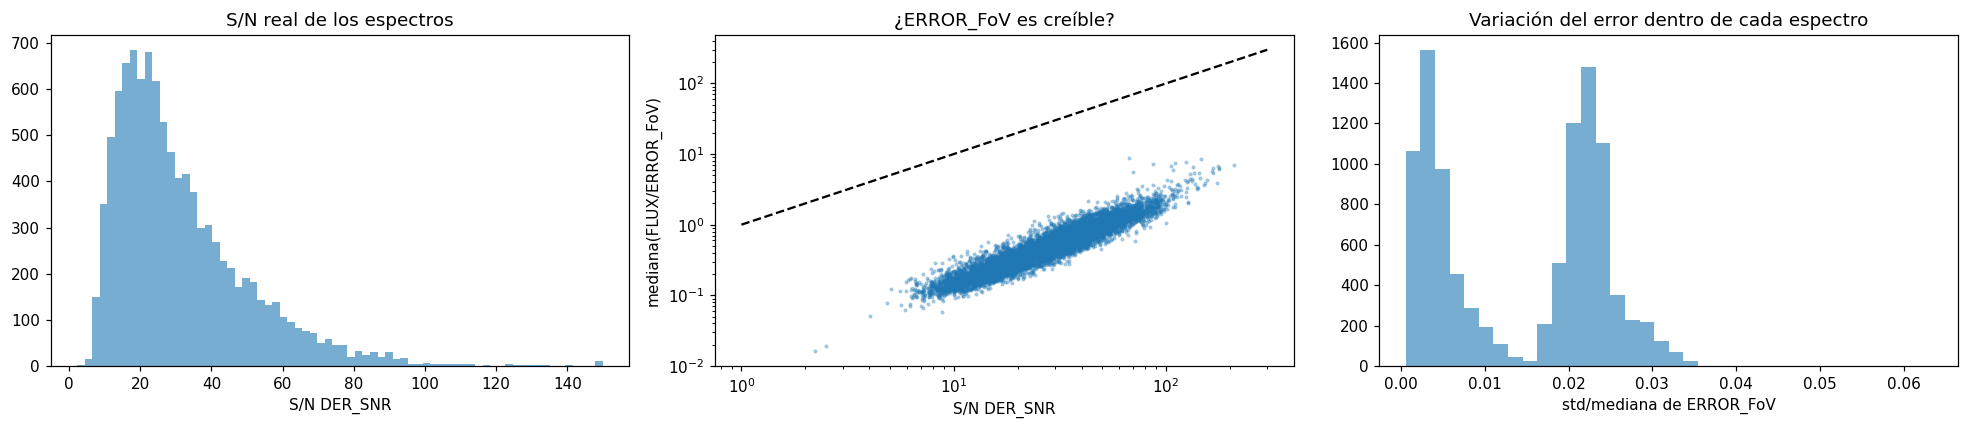

In [14]:
cols_qa = ['n_pix', 'lam_min', 'lam_max', 'paso_min', 'paso_max', 'n_cero', 'n_neg', 'n_nan',
           'flux_mediana', 'snr_der', 'snr_err', 'err_cv']
display(crudo[cols_qa].describe(percentiles=[0.01, 0.5, 0.99]).T.round(3))
print('Espectros con huecos:', (crudo['paso_max'] > crudo['paso_min'] + 1e-6).sum())
print('Espectros con flujo negativo:', (crudo['n_neg'] > 0).sum())

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
hist_astro(crudo['snr_der'].dropna().clip(0, 150), bins='knuth', ax=ax[0], histtype='stepfilled', alpha=0.6)
ax[0].set_xlabel('S/N DER_SNR'); ax[0].set_title('S/N real de los espectros')
ax[1].scatter(crudo['snr_der'], crudo['snr_err'], s=3, alpha=0.3)
ax[1].set_xscale('log'); ax[1].set_yscale('log'); ax[1].plot([1, 300], [1, 300], 'k--')
ax[1].set_xlabel('S/N DER_SNR'); ax[1].set_ylabel('mediana(FLUX/ERROR_FoV)'); ax[1].set_title('¿ERROR_FoV es creíble?')
hist_astro(crudo['err_cv'].dropna(), bins='knuth', ax=ax[2], histtype='stepfilled', alpha=0.6)
ax[2].set_xlabel('std/mediana de ERROR_FoV'); ax[2].set_title('Variación del error dentro de cada espectro')
plt.tight_layout(); plt.show()

**Conclusión 4.2:**
* Todos los FITS deberían tener 4487 píxeles, sin huecos. Los pocos 0 están en los bordes y se convierten a NaN.
* `ERROR_FoV` casi no varía (`err_cv` ≈ 0.01–0.02) y su S/N no sigue a DER_SNR. **Confirmado: es incorrecto.**
* Si STARLIGHT usó ese error, su χ² **no tiene sentido en valor absoluto**. Para juzgar el ajuste usamos `adev`.

,count,mean,std,min,1%,50%,99%,max
chi2,10243.0,1.128,0.434,0.046,0.339,1.117,2.188,2.937
adev,10243.0,3.605,1.763,1.147,1.632,3.141,9.815,24.454
SN_SL,10243.0,32.494,9.677,1.503,12.002,32.119,62.257,110.352
suma_x,10243.0,104.774,3.408,82.024,98.895,104.275,116.790,130.000
v0,10243.0,86.225,39.269,-487.190,-41.049,87.450,195.723,498.320
sigma_estelar,10243.0,138.217,71.951,0.000,25.304,124.460,359.352,499.280
AV_estelar,10243.0,0.232,0.241,-0.674,-0.152,0.206,0.861,2.751
frac_recortada,10243.0,0.088,0.093,0.000,0.003,0.067,0.428,1.926


flag_clip_bug {0: 10243}
flag_rc_crash {0: 10243}
flag_burn_in {1: 10242, 0: 1}
Fracción con σ < 70 km/s (no fiable): 0.155
A_V estelar < 0: 1700


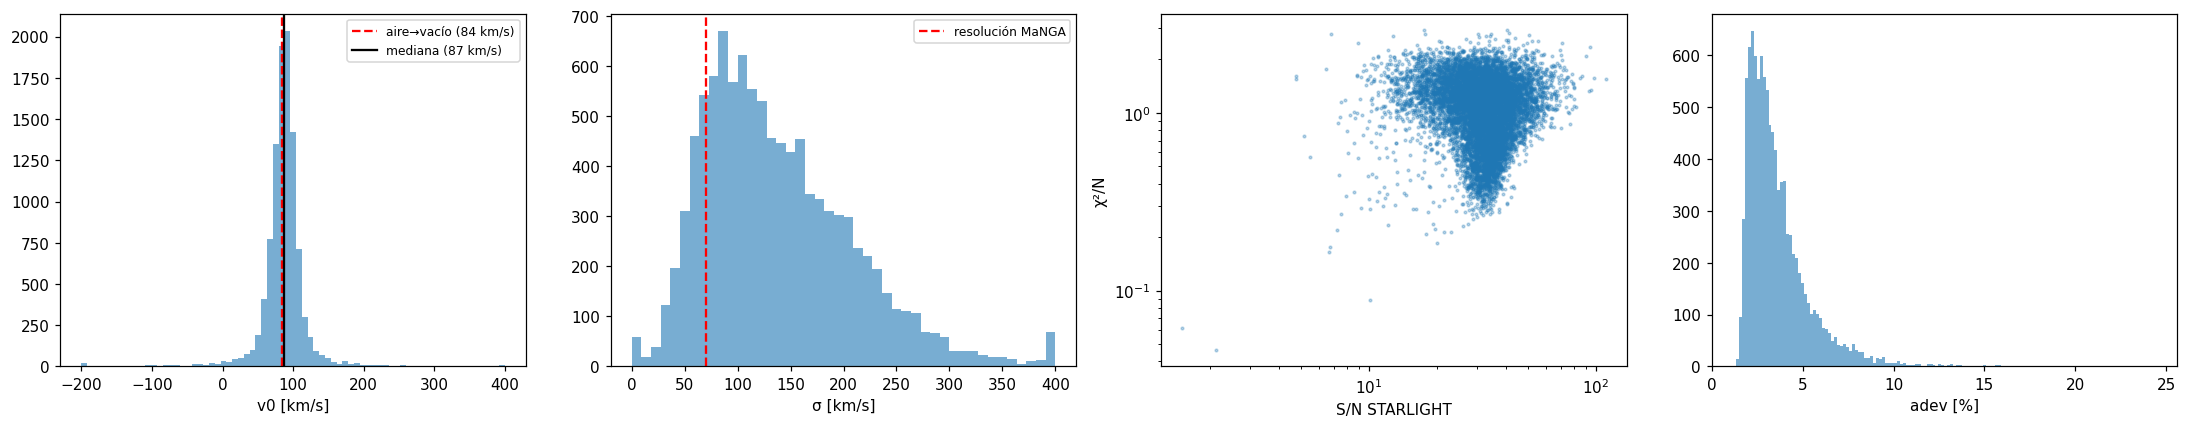

In [15]:
cols_sl = ['chi2', 'adev', 'SN_SL', 'suma_x', 'v0', 'sigma_estelar', 'AV_estelar', 'frac_recortada']
display(crudo[cols_sl].describe(percentiles=[0.01, 0.5, 0.99]).T.round(3))
for b in ['flag_clip_bug', 'flag_rc_crash', 'flag_burn_in']:
    print(b, crudo[b].value_counts(dropna=False).to_dict())
print('Fracción con σ < 70 km/s (no fiable):', round((crudo['sigma_estelar'] < 70).mean(), 3))
print('A_V estelar < 0:', (crudo['AV_estelar'] < 0).sum())

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
v0 = crudo['v0'].dropna()
hist_astro(v0.clip(-200, 400), bins='knuth', ax=ax[0], histtype='stepfilled', alpha=0.6)
ax[0].axvline(V_AIRE_VACIO, color='r', ls='--', label=f'aire→vacío ({V_AIRE_VACIO:.0f} km/s)')
ax[0].axvline(v0.median(), color='k', label=f'mediana ({v0.median():.0f} km/s)')
ax[0].set_xlabel('v0 [km/s]'); ax[0].legend(fontsize=8)
hist_astro(crudo['sigma_estelar'].dropna().clip(0, 400), bins='knuth', ax=ax[1], histtype='stepfilled', alpha=0.6)
ax[1].axvline(70, color='r', ls='--', label='resolución MaNGA'); ax[1].set_xlabel('σ [km/s]'); ax[1].legend(fontsize=8)
ax[2].scatter(crudo['SN_SL'], crudo['chi2'], s=3, alpha=0.3); ax[2].set_xscale('log'); ax[2].set_yscale('log')
ax[2].set_xlabel('S/N STARLIGHT'); ax[2].set_ylabel('χ²/N')
hist_astro(crudo['adev'].dropna().clip(0, 30), bins='knuth', ax=ax[3], histtype='stepfilled', alpha=0.6)
ax[3].set_xlabel('adev [%]')
plt.tight_layout(); plt.show()

**Conclusión 4.3:**
* La **mediana de v0 ≈ 85–90 km/s** coincide con el offset aire→vacío (≈ 83 km/s). No es un error de redshift. El EDA dividía
  por (1 + v0/c) y llevaba el espectro al sistema **de aire**; aquí se corrige.
* σ < 70 km/s está por debajo de la resolución y **no es fiable** (típico de Sc–Im). En 6.7 le ponemos un piso.
* χ² crece con la S/N (desajuste de plantillas) y su escala depende del error usado, por eso se filtra con `adev`.

### 4.4 Calidad del catálogo morfológico
Buscamos centinelas, valores imposibles, topes, valores repetidos y etiquetas `Type`/`Ttype` inconsistentes.

,n_galaxias
nsa_z = −9999 (centinela),27
nsa_z nulo,1
nsa_z negativo (≠ −9999),1
0 < z < 0.005 (distancia no fiable),8
LogMass nulo,28
LogMass < 7.5 o > 12.5,8
incl = 0°,8
incl en el tope ≥ 81.37°,179
PETRO_TH90 nulo,33
PETRO_TH90 > 80″,44


Etiquetas inconsistentes:


,Type,Ttype,Ttype_esperado
name,,,
manga-9025-1901,Sa,3,1


Valores de PETRO_TH90 repetidos ≥ 3 veces (sospecha de valor por defecto):


,veces
PETRO_TH90,
15.164000,40
10.924000,38
18.740000,37
9.986000,36
16.906000,32
15.515000,32
15.784000,31
14.077000,30
18.004999,30


Ttype,-5,-2,0,1,2,3,4,5,6,7,8,9,10,11
Type,,,,,,,,,,,,,,
BCD,0,0,0,0,0,0,0,0,0,0,0,0,2,0
E,972,0,0,0,0,0,0,0,0,0,0,0,0,0
E(dSph),7,0,0,0,0,0,0,0,0,0,0,0,0,0
E+E,2,0,0,0,0,0,0,0,0,0,0,0,0,0
Edc,828,0,0,0,0,0,0,0,0,0,0,0,0,0
Irr,0,0,0,0,0,0,0,0,0,0,0,0,7,0
IrrAB,0,0,0,0,0,0,0,0,0,0,0,0,1,0
IrrB,0,0,0,0,0,0,0,0,0,0,0,0,2,0
S,0,0,0,0,0,0,0,0,0,0,0,0,0,42


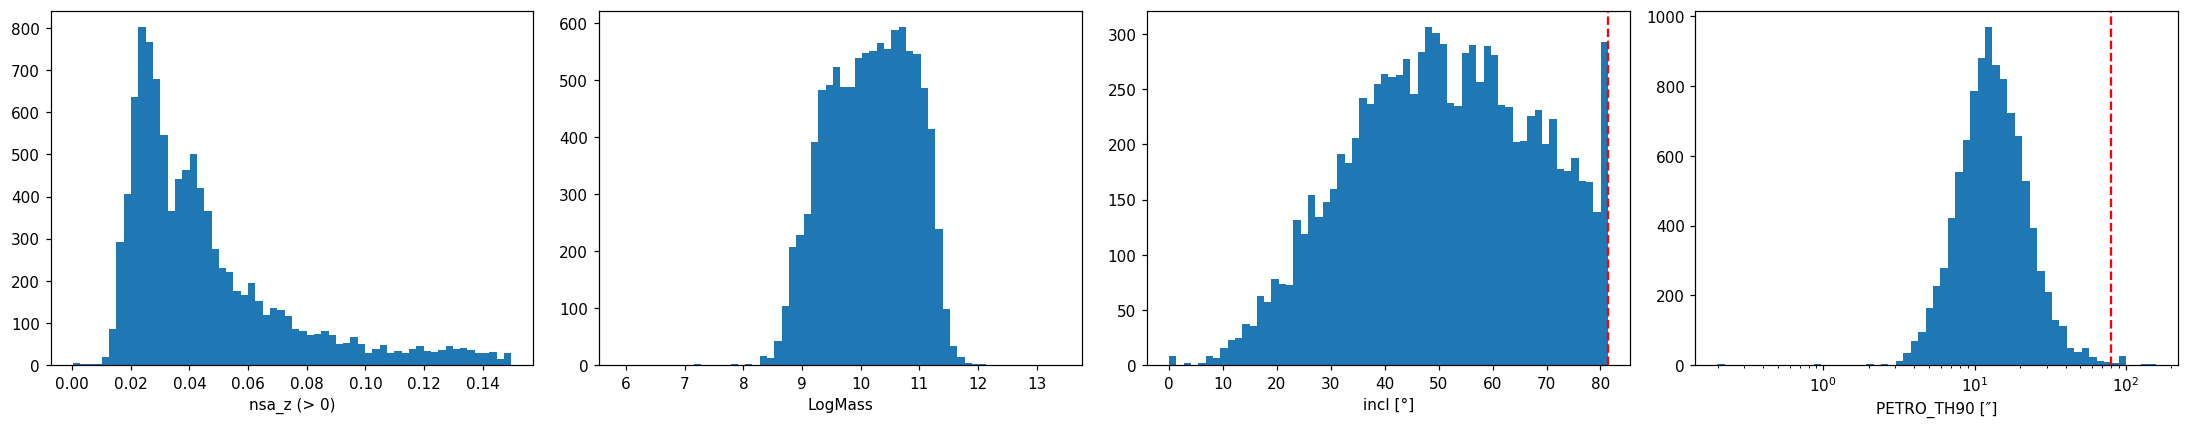

In [16]:
cat = morf_raw
tipos_merger = ['S-merger', 'SAB-merger', 'interacting', 'E+E']
problemas = pd.Series({
    'nsa_z = −9999 (centinela)': (cat['nsa_z'] == -9999).sum(),
    'nsa_z nulo': cat['nsa_z'].isna().sum(),
    'nsa_z negativo (≠ −9999)': ((cat['nsa_z'] < 0) & (cat['nsa_z'] != -9999)).sum(),
    '0 < z < 0.005 (distancia no fiable)': ((cat['nsa_z'] > 0) & (cat['nsa_z'] < 0.005)).sum(),
    'LogMass nulo': cat['LogMass'].isna().sum(),
    'LogMass < 7.5 o > 12.5': ((cat['LogMass'] < 7.5) | (cat['LogMass'] > 12.5)).sum(),
    'incl = 0°': (cat['incl'] == 0).sum(),
    'incl en el tope ≥ 81.37°': (cat['incl'] >= 81.37).sum(),
    'PETRO_TH90 nulo': cat['PETRO_TH90'].isna().sum(),
    'PETRO_TH90 > 80″': (cat['PETRO_TH90'] > 80).sum(),
    'Ttype = 11 (no ordinal)': (cat['Ttype'] == 11).sum(),
    'Type incompatible con Ttype': (cat['Ttype_esperado'] != cat['Ttype']).sum(),
    'Enanas esferoidales (dSph, E(dSph))': cat['Type'].isin(['dSph', 'E(dSph)']).sum(),
    'Mergers / interacción': cat['Type'].isin(tipos_merger).sum(),
    'Nombres duplicados': cat.index.duplicated().sum(),
}, name='n_galaxias')
display(problemas.to_frame())

print('Etiquetas inconsistentes:')
display(cat.loc[cat['Ttype_esperado'] != cat['Ttype'], ['Type', 'Ttype', 'Ttype_esperado']])
print('Valores de PETRO_TH90 repetidos ≥ 3 veces (sospecha de valor por defecto):')
rep = cat['PETRO_TH90'].round(3).value_counts()
display(rep[rep >= 3].head(15).to_frame('veces'))
display(pd.crosstab(cat['Type'], cat['Ttype']))

fig, ax = plt.subplots(1, 4, figsize=(20, 4))
ax[0].hist(cat['nsa_z'][cat['nsa_z'] > 0], bins=60); ax[0].set_xlabel('nsa_z (> 0)')
ax[1].hist(cat['LogMass'].dropna(), bins=60); ax[1].set_xlabel('LogMass')
ax[2].hist(cat['incl'].dropna(), bins=60); ax[2].axvline(81.37, color='r', ls='--'); ax[2].set_xlabel('incl [°]')
ax[3].hist(cat['PETRO_TH90'].dropna(), bins=np.logspace(-0.7, 2.2, 60)); ax[3].set_xscale('log')
ax[3].axvline(80, color='r', ls='--'); ax[3].set_xlabel('PETRO_TH90 [″]')
plt.tight_layout(); plt.show()

**Conclusión 4.4** (lo encontrado al revisar el `morfologia.fits` del repositorio):
* **27 galaxias con nsa_z = −9999**, 1 con z negativo y 1 nula. Ninguna tiene espectro. Hay galaxias con z ≈ 0.0002.
* **Etiqueta inconsistente:** 1 galaxia `Sa` con T = 3. Se elimina.
* **T = −5 mezcla** E, Edc, 7 E(dSph) y 2 E+E. **T = 10 mezcla** Irr, dIrr, BCD, 4 dSph y "dwarf". Las dSph no pertenecen a la
  secuencia de Hubble y se eliminan.
* **T = 11** (67): S/SAB sin estadio y mergers. No es ordinal y se excluye.
* **incl** tiene un tope en 81.37° (cos i = 0.15, probablemente un piso de b/a) y 8 valores de 0°.
* **PETRO_TH90:** ~45 valores > 80″, con repetidos (96.698, 93.761…): fallos de la fotometría NSA, así que se marcan como NaN.
* **LogMass:** extremos de 5.9 y 13.4. Se pasan a NaN fuera de [7.5, 12.5].

### 4.5 Outliers y valores inusuales
Usamos dos criterios robustos:
* **z robusto** = (x − mediana)/σ_G (astroML). Outlier si |z| > 5.
* **Regla de Tukey** con 3·IQR.

El catálogo se analiza **crudo** para que salgan los centinelas.

In [ ]:
def z_robusto(x):
    return (x - np.nanmedian(x)) / sigmaG(x.dropna())

def tabla_outliers(df, columnas, k=5):
    filas = []
    for col in columnas:
        x = df[col].dropna().astype(float)
        if len(x) < 10 or sigmaG(x) == 0:
            continue
        q1, q3 = np.percentile(x, [25, 75]); iqr = q3 - q1
        filas.append({'feature': col, 'n': len(x), 'mediana': x.median(), 'sigmaG': sigmaG(x),
                      f'n_|z_rob|>{k}': int((z_robusto(x).abs() > k).sum()),
                      'n_fuera_3IQR': int(((x < q1 - 3 * iqr) | (x > q3 + 3 * iqr)).sum()),
                      'min': x.min(), 'max': x.max()})
    return pd.DataFrame(filas).set_index('feature').round(3)

entrada = crudo.join(morf_raw[['nsa_z', 'LogMass', 'incl', 'PETRO_TH90', 'Ttype']], how='inner')
cols_entrada = ['nsa_z', 'LogMass', 'incl', 'PETRO_TH90', 'snr_der', 'flux_mediana', 'SN_SL', 'chi2', 'adev', 'v0',
                'sigma_estelar', 'AV_estelar', 'logEdad_L', 'logEdad_M', 'logZ_L', 'xY', 'xO', 'D4000n', 'EW_Ha_6563']
display(tabla_outliers(entrada, cols_entrada))

zr = entrada[cols_entrada].apply(z_robusto).clip(-15, 15)
plt.figure(figsize=(18, 4))
sns.boxplot(data=zr, fliersize=1); plt.axhline(5, color='r', ls='--'); plt.axhline(-5, color='r', ls='--')
plt.xticks(rotation=60); plt.ylabel('z robusto (recortado a ±15)'); plt.title('Outliers de las variables de entrada')
plt.show()

**Conclusión 4.5:**
* Los outliers de `nsa_z` son los centinelas −9999: son **errores**.
* En `EW_Ha` y `xY`, los "outliers" son **reales** (starbursts). Eliminarlos quitaría justamente a las tardías.
  → **No se eliminan outliers astrofísicos**: solo se corrigen los errores y se **winsoriza** al percentil 0.5/99.5 (sección 7).
* `chi2` y `adev` altos señalan malos ajustes y se filtran en la sección 5.

### 4.6 Correlaciones entre variables numéricas
Usamos Spearman porque es robusto y detecta relaciones monótonas no lineales. Aquí se usa el catálogo **limpio**.

In [ ]:
entrada_limpia = crudo.join(morf[['nsa_z', 'LogMass', 'incl', 'PETRO_TH90', 'Ttype']], how='inner')
entrada_limpia = entrada_limpia[entrada_limpia['Ttype'] != 11]
cols_corr = cols_entrada + ['Ttype']
corr = entrada_limpia[cols_corr].corr(method='spearman')

plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlación de Spearman (entradas)'); plt.show()

triangulo = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
display(triangulo.reindex(triangulo.abs().sort_values(ascending=False).index).head(20).to_frame('rho').round(2))

# Efecto de selección de MaNGA: masa vs z, coloreado por T-type
plt.figure(figsize=(7, 5))
for t in [t for t in ORDEN_TTYPE if t != 11]:
    s = entrada_limpia[entrada_limpia['Ttype'] == t]
    plt.scatter(s['nsa_z'], s['LogMass'], s=4, color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t])
plt.xlabel('z'); plt.ylabel('log M*'); plt.legend(ncol=2, fontsize=7); plt.title('Selección MaNGA: M* vs z'); plt.show()

**Conclusión 4.6:**
* **Bloque "edad":** D4000n, logEdad_L, xO, xY y EW(Hα) están muy correlacionados (|ρ| > 0.8). Miden lo mismo
  (Kauffmann et al. 2003a).
* **LogMass–σ** (Faber & Jackson 1976) y **LogMass–edad/metalicidad** (*downsizing*; Gallazzi et al. 2005).
* **z–LogMass** es positiva **por diseño** (Wake et al. 2017). → `nsa_z` **no se usa como feature**.
* `PETRO_TH90` (en ″) depende de la distancia y se convierte a kpc en la sección 6.

### 4.7 ¿Qué tablas se pueden unir y cómo validar el cruce?
| Unión | Clave | Validación |
|---|---|---|
| FITS ↔ `.out` | nombre `manga-<plate>-<ifu>` | `arq_obs` escrito **dentro** del `.out` |
| FITS/`.out` ↔ catálogo | `name` | v0 ≈ +83 km/s (con un z ajeno, v0 sería enorme) |
| Catálogo ↔ catálogo | coordenadas (`SkyCoord`, < 3″) | **la misma galaxia observada con dos IFU** |
| Catálogo ↔ DRPall DR17 (opcional) | `plateifu` **y** posición | separación < 1″, Δz ≈ 0, `mangaid` común |

In [ ]:
n_fits, n_out, n_cat = set(nombre_galaxia(p) for p in fits_files), set(outs), set(morf_raw.index)
display(pd.Series({'FITS': len(n_fits), '.out': len(n_out), 'catálogo': len(n_cat),
                   'FITS ∩ .out': len(n_fits & n_out), 'FITS ∩ catálogo': len(n_fits & n_cat),
                   'FITS ∩ .out ∩ catálogo': len(n_fits & n_out & n_cat),
                   'FITS sin catálogo': len(n_fits - n_cat), 'catálogo sin FITS': len(n_cat - n_fits),
                   'FITS sin .out': len(n_fits - n_out)}, name='n').to_frame())
print('Ejemplos de FITS sin catálogo:', sorted(n_fits - n_cat)[:10])
print('Catálogo sin FITS:')
display(morf_raw.loc[sorted(n_cat - n_fits), ['Type', 'Ttype', 'nsa_z']])

# Validación 1: el nombre de entrada dentro del .out coincide con el nombre del archivo
interno = crudo['arq_obs'].dropna().astype(str).str.split('-1D').str[0]
print(f'arq_obs coincide con el nombre del archivo: {(interno == interno.index).sum()} de {len(interno)}')

# Validación 2: consistencia espectroscópica del z del catálogo
dv = (crudo['v0'] - V_AIRE_VACIO).reindex(sorted(n_fits & n_cat))
print('Galaxias con |v0 − 83| > 300 km/s (z dudoso o mal cruce):', (dv.abs() > 300).sum())

# Validación 3: la misma galaxia observada dos veces (coordenadas < 3″)
coords = SkyCoord(morf_raw['objra'].values * u.deg, morf_raw['objdec'].values * u.deg)
i1, i2, sep, _ = coords.search_around_sky(coords, 3 * u.arcsec)
m = i1 < i2                                               # quitamos autocoincidencias y pares repetidos
duplicados = pd.DataFrame({'gal_1': morf_raw.index[i1[m]], 'gal_2': morf_raw.index[i2[m]],
                           'sep_arcsec': sep[m].arcsec.round(2),
                           'T_1': morf_raw['Ttype'].values[i1[m]], 'T_2': morf_raw['Ttype'].values[i2[m]],
                           'z_1': morf_raw['nsa_z'].values[i1[m]], 'z_2': morf_raw['nsa_z'].values[i2[m]]})
print(f'{len(duplicados)} pares de la misma galaxia; con T distinto: {(duplicados.T_1 != duplicados.T_2).sum()}')
display(duplicados)

**Validación externa (opcional) con el DRPall de MaNGA DR17.** Contiene `plateifu`, `mangaid`, coordenadas, z y bits de
selección (`mngtarg1 = 0` ⇒ fuera de la muestra principal). Pesa cientos de MB. Si la descarga falla, el notebook sigue.

In [ ]:
URL_DRPALL = 'https://data.sdss.org/sas/dr17/manga/spectro/redux/v3_1_1/drpall-v3_1_1.fits'
try:
    t = Table.read(download_file(URL_DRPALL, cache=True, timeout=600), hdu=1)
    cols = [col for col in ['plateifu', 'mangaid', 'objra', 'objdec', 'nsa_z', 'z', 'mngtarg1', 'mngtarg3'] if col in t.colnames]
    drp = t[cols].to_pandas()                             # solo columnas escalares
    for col in ['plateifu', 'mangaid']:
        drp[col] = drp[col].apply(lambda v: v.decode().strip() if isinstance(v, bytes) else str(v).strip())
    drp['name'] = 'manga-' + drp['plateifu']
    drp = drp.drop_duplicates('name').set_index('name')
except Exception as e:
    print('No se pudo usar DRPall:', e)
    drp = None

if drp is not None:
    comunes = morf_raw.index.intersection(drp.index)
    a = SkyCoord(morf_raw.loc[comunes, 'objra'].values * u.deg, morf_raw.loc[comunes, 'objdec'].values * u.deg)
    b = SkyCoord(drp.loc[comunes, 'objra'].values * u.deg, drp.loc[comunes, 'objdec'].values * u.deg)
    sep = a.separation(b).arcsec
    print(f'Cruce por nombre: {len(comunes)} | separación > 1″: {(sep > 1).sum()} | mediana {np.median(sep):.3f}″')
    dz = (morf_raw.loc[comunes, 'nsa_z'] - drp.loc[comunes, 'nsa_z']).abs()
    print('|Δz| > 0.001:', (dz > 0.001).sum())

    # Cruce por POSICIÓN, independiente del nombre: ¿la más cercana en DRPall tiene el mismo mangaid?
    todos = SkyCoord(drp['objra'].values * u.deg, drp['objdec'].values * u.deg)
    idx, d2, _ = a.match_to_catalog_sky(todos)
    mismo = drp['mangaid'].values[idx] == drp.loc[comunes, 'mangaid'].values
    print(f'Cruce por posición devuelve el mismo mangaid: {mismo.sum()} de {len(comunes)}')

    # ¿Qué son los espectros sin catálogo?
    sin_cat = drp.reindex(sorted(n_fits - n_cat))
    print('Espectros sin catálogo fuera de la muestra principal (mngtarg1 = 0):', (sin_cat['mngtarg1'] == 0).sum())
    # ¿DRPall tiene redshift para los centinelas −9999?
    display(drp.reindex(morf_raw.index[morf_raw['nsa_z'] == -9999])[[col for col in ['nsa_z', 'z'] if col in drp]].head(10))

**Conclusión 4.7** (cifras de la revisión de los archivos del repositorio):
* **10 243 FITS = 10 243 `.out`**, con los mismos nombres: el cruce es 1 a 1.
* **10 096** galaxias tienen espectro y catálogo. **147 espectros no tienen catálogo** (probablemente objetivos auxiliares).
  **30 del catálogo no tienen espectro** (27 con z = −9999).
* **9 pares** son la misma galaxia observada con dos IFU, con el mismo T. Dejar ambas produce **fuga entre train y test**.
  Se conserva la de mayor S/N.
* Que v0 ≈ 83 km/s en casi todas indica que **el cruce por nombre es correcto**.

# 5. Limpieza y preprocesamiento
Cada filtro tiene una justificación física o de calidad, y se registra cuántas galaxias elimina **por clase**.

| Paso | Por qué |
|---|---|
| z inválido | no se puede pasar al reposo |
| T = 11 | no es ordinal |
| dSph, E(dSph), E+E y mergers | fuera de la secuencia de Hubble o perturbadas |
| Type ≠ Ttype | etiqueta contradictoria |
| S/N < 10 | índices poco fiables |
| \|v0 − 83\| > 300 km/s | z dudoso |
| adev extremo | mal ajuste de STARLIGHT |
| > 20 % de la rejilla vacía | PCA poco fiable |
| duplicados < 3″ | fuga entre train y test |

In [ ]:
df = crudo.join(morf, how='inner')                        # solo espectros con entrada en el catálogo
conteo_inicial = df['Ttype'].value_counts().sort_index()
df['frac_nan_grid'] = np.isnan(matriz_df.loc[df.index].values).mean(axis=1)

pasos = [('espectros con catálogo', 0, len(df))]
def filtrar(df, condicion, motivo):
    condicion = np.asarray(condicion, dtype=bool)
    pasos.append((motivo, int((~condicion).sum()), int(condicion.sum())))
    return df[condicion]

TIPOS_FUERA = ['dSph', 'E(dSph)', 'E+E', 'S-merger', 'SAB-merger', 'interacting']
df = filtrar(df, df['nsa_z'].notna(), 'z inválido')
df = filtrar(df, df['logEdad_L'].notna(), 'sin STARLIGHT legible')
df = filtrar(df, df['Ttype'] != 11, 'T = 11 (no ordinal)')
df = filtrar(df, ~df['Type'].isin(TIPOS_FUERA), 'dSph, E(dSph), E+E, mergers')
df = filtrar(df, df['Ttype_esperado'] == df['Ttype'], 'Type y Ttype inconsistentes')
df = filtrar(df, df['SN_SL'] >= 10, 'S/N < 10')
df = filtrar(df, (df['v0'] - V_AIRE_VACIO).abs() < 300, '|v0 − 83| > 300 km/s')
lim_adev = df['adev'].median() + 5 * sigmaG(df['adev'].dropna())
df = filtrar(df, df['adev'] < lim_adev, f'adev > {lim_adev:.1f} % (mal ajuste)')
df = filtrar(df, df['frac_nan_grid'] < 0.2, 'rejilla espectral incompleta')

# Duplicados por posición: se conserva la observación con mayor S/N
coords = SkyCoord(df['objra'].values * u.deg, df['objdec'].values * u.deg)
i1, i2, _, _ = coords.search_around_sky(coords, 3 * u.arcsec)
quitar = set()
for a, b in zip(i1, i2):
    if a < b:
        quitar.add(df.index[b] if df['SN_SL'].iloc[a] >= df['SN_SL'].iloc[b] else df.index[a])
df = filtrar(df, ~df.index.isin(quitar), 'observación repetida (< 3″)')

display(pd.DataFrame(pasos, columns=['paso', 'eliminadas', 'quedan']))
display(pd.DataFrame({'inicial': conteo_inicial, 'final': df['Ttype'].value_counts()}).fillna(0).astype(int)
          .assign(fraccion_conservada=lambda t: (t['final'] / t['inicial']).round(2)))

**Conclusión 5:** la fracción conservada debería ser parecida en todos los T-types. Si el corte de S/N eliminara sobre todo a las
Sd–Im, habría que bajarlo a S/N ≥ 5. De lo contrario, el clasificador aprendería un sesgo de selección.

### 5.1 División train/test **antes** de todo lo que aprende de los datos
PCA, winsorización, imputación, balanceo y selección se ajustan **solo con train**. La división se estratifica por T-type.

In [ ]:
idx_train, idx_test = train_test_split(df.index, test_size=0.25, stratify=df['Ttype'], random_state=SEMILLA)
es_train = df.index.isin(idx_train)
print(len(idx_train), 'train |', len(idx_test), 'test')

### 5.2 PCA de los espectros (ajustado solo con train)
El PCA espectral (Connolly et al. 1995; Yip et al. 2004) resume la forma del espectro. En el EDA, PC1 explicaba ~55 %.
* Los NaN (por el cielo enmascarado) se rellenan con la mediana de train en esa λ.
* Solo se usan las λ con datos en ≥ 98 % de train.

In [ ]:
M = matriz_df.loc[df.index].values
cols_ok = np.isfinite(M[es_train]).mean(axis=0) > 0.98
mediana_train = np.nanmedian(M[es_train][:, cols_ok], axis=0)
X_esp = np.where(np.isfinite(M[:, cols_ok]), M[:, cols_ok], mediana_train)

pca = PCA(n_components=10, random_state=SEMILLA).fit(X_esp[es_train])
proy = pca.transform(X_esp)
for k in range(5):
    df[f'PC{k + 1}'] = proy[:, k]
print('Varianza explicada:', pca.explained_variance_ratio_[:5].round(3))

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for t in [t for t in ORDEN_TTYPE if t != 11]:
    s = df[df['Ttype'] == t]
    ax[0].scatter(s['PC1'], s['PC2'], s=4, color=COLOR_TTYPE[t], label=NOMBRE_TTYPE[t])
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(ncol=2, fontsize=7)
ax[1].plot(GRID[cols_ok], pca.mean_, 'k', lw=1, label='media')
for k in range(3):
    ax[1].plot(GRID[cols_ok], pca.components_[k] * 5 + 1 + k, lw=0.8, label=f'PC{k + 1} (×5, desplazada)')
ax[1].set_xlabel('λ en reposo [Å]'); ax[1].legend(); ax[1].set_title('Eigenespectros')
plt.tight_layout(); plt.show()

**Conclusión 5.2:** **PC1** debería representar la pendiente del continuo y el quiebre de 4000 Å (edad) y ordenar de E a Im.
**PC2** suele capturar las líneas de emisión. Si los T-types forman un continuo en PC1–PC2, la morfología es una **secuencia**
y los tipos vecinos se solapan.

# 6. Ingeniería de features (con motivación astrofísica)
Agrupamos las features en **familias físicas** para responder qué *física* distingue a la morfología.

| Familia | Features nuevas | Por qué |
|---|---|---|
| Edad / historia | Δedad = logEdad_M − logEdad_L, índices `_syn` | Δedad grande = estrellas jóvenes sobre una base vieja (bulbo + disco) |
| Formación estelar actual | log EW, log sSFR(Hα) | SFR/M* (Kennicutt & Evans 2012) |
| Química | [MgFe]′, Mg b/⟨Fe⟩, 12+log(O/H) | [MgFe]′ casi no depende de α/Fe (Thomas et al. 2003); Mg b/⟨Fe⟩ es mayor si la formación fue rápida (Thomas et al. 2005) |
| Polvo | A_V del gas, Hα/Hβ, NaD_ISM | discos con gas y polvo frente a esferoides limpios |
| Ionización | cocientes BPT, BPT/WHAN | H II frente a LINER/retiradas |
| Masa, cinemática y estructura | log σ, log R90 [kpc], log Σ*₉₀, b/a | Σ* traza el bulbo (Kauffmann et al. 2003b); σ el soporte por presión |

* El tamaño, la Σ* y la sSFR se ponen como NaN si z < 0.005.
* **Unidades:** `FLUX_FoV` se supone en 10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹. Si no lo fuera, log sSFR se desplaza una constante, lo que no
  cambia los rankings.

In [ ]:
SN_MIN = 3
def detectada(*lineas):
    """True si TODAS las líneas tienen S/N ≥ SN_MIN."""
    ok = pd.Series(True, index=df.index)
    for l in lineas:
        ok &= df[f'SN_{l}'] >= SN_MIN
    return ok

def log_cociente(num, den):
    """log10(F_num/F_den), solo si ambas líneas están detectadas."""
    return np.log10(df[f'F_{num}'] / df[f'F_{den}']).where(detectada(num, den))

z_ok = df['nsa_z'] >= 0.005                                   # distancia fiable

# --- 6.1 Edad e historia de formación estelar ---
df['Delta_edad'] = df['logEdad_M'] - df['logEdad_L']

# --- 6.2 Formación estelar actual ---
for linea in ['Ha_6563', 'Hb_4861', 'OII_3727', 'NII_6584', 'OIII_5007', 'SII_6717']:
    df[f'log_EW_{linea.split("_")[0]}'] = np.log10(df[f'EW_{linea}'].clip(lower=0.1))   # piso de 0.1 Å
df['Ha_detectada'] = detectada('Ha_6563').astype(int)

# --- 6.3 Ionización ---
df['log_NII_Ha'] = log_cociente('NII_6584', 'Ha_6563')
df['log_OIII_Hb'] = log_cociente('OIII_5007', 'Hb_4861')
df['log_OI_Ha'] = log_cociente('OI_6300', 'Ha_6563')
ok_sii = detectada('SII_6717', 'SII_6731', 'Ha_6563')
df['log_SII_Ha'] = np.log10((df['F_SII_6717'] + df['F_SII_6731']) / df['F_Ha_6563']).where(ok_sii)

# BPT (Baldwin et al. 1981; Kauffmann et al. 2003c; Kewley et al. 2001, 2006)
ka03     = lambda x: 0.61 / (x - 0.05) + 1.30
ke01_nii = lambda x: 0.61 / (x - 0.47) + 1.19
def clase_bpt(x, y, x_sii):
    if np.isnan(x) or np.isnan(y):    return 'Sin líneas'
    if x < 0.05 and y < ka03(x):      return 'SF'
    if x < 0.47 and y < ke01_nii(x):  return 'Compuesta'
    if not np.isnan(x_sii):           return 'Seyfert' if y > 1.89 * x_sii + 0.76 else 'LINER'
    return 'Seyfert' if y > 1.05 * x + 0.45 else 'LINER'
df['BPT'] = [clase_bpt(x, y, s) for x, y, s in zip(df['log_NII_Ha'], df['log_OIII_Hb'], df['log_SII_Ha'])]

# WHAN (Cid Fernandes et al. 2011): también clasifica a las galaxias de líneas débiles
def clase_whan(ew_ha, ew_nii, x):
    if np.isnan(ew_ha):               return 'Sin datos'
    if ew_ha < 0.5 and ew_nii < 0.5:  return 'Pasiva'
    if ew_ha < 3:                     return 'Retirada'
    if np.isnan(x):                   return 'Indeterminada'
    if x < -0.4:                      return 'SF'
    return 'sAGN' if ew_ha > 6 else 'wAGN'
x_whan = np.log10(df['F_NII_6584'] / df['F_Ha_6563']).where(detectada('Ha_6563') & (df['SN_NII_6584'] >= 2))
df['WHAN'] = [clase_whan(a, b, x) for a, b, x in zip(df['EW_Ha_6563'], df['EW_NII_6584'], x_whan)]

In [ ]:
# --- 6.4 Polvo ---
ok_balmer = detectada('Ha_6563', 'Hb_4861')
cociente_balmer = (df['F_Ha_6563'] / df['F_Hb_4861']).where(ok_balmer)
df['log_HaHb'] = np.log10(cociente_balmer)
# Decremento de Balmer: caso B, Hα/Hβ = 2.86 (Osterbrock & Ferland 2006); ley de Cardelli et al. (1989),
# k(Hβ) = 3.61 y k(Hα) = 2.53
df['AV_gas'] = (3.1 * 2.5 / (3.61 - 2.53) * np.log10(cociente_balmer / 2.86)).clip(lower=0)
df['NaD_ISM'] = df['NaD'] - df['NaD_syn']                     # exceso de Na D sobre el modelo estelar = gas frío

# --- 6.5 Química ---
fe_medio = (df['Fe5270'] + df['Fe5335']) / 2
fe_ponderado = 0.72 * df['Fe5270'] + 0.28 * df['Fe5335']      # Thomas et al. 2003
df['MgFe'] = np.sqrt((df['Mgb'] * fe_ponderado).where((df['Mgb'] > 0) & (fe_ponderado > 0)))
df['Mgb_Fe'] = (df['Mgb'] / fe_medio).where(fe_medio > 0.5)   # evita dividir por ~0
df['CaT'] = df['CaT1'] + df['CaT2'] + df['CaT3']
df['OH_N2'] = (8.90 + 0.57 * df['log_NII_Ha']).where(df['BPT'] == 'SF')   # Pettini & Pagel 2004, solo regiones H II

# --- 6.6 SFR específica a partir de Hα corregido por polvo (Kennicutt & Evans 2012) ---
A_Ha = (2.53 / 3.1) * df['AV_gas'].fillna(0)
d_L = cosmo.luminosity_distance(df['nsa_z'].values).to(u.cm).value
L_Ha = 4 * np.pi * d_L ** 2 * df['F_Ha_6563'] * 1e-17 * 10 ** (0.4 * A_Ha)   # supone flujo en 1e-17 erg/s/cm²
log_ssfr = np.log10(L_Ha) - 41.27 - df['LogMass']
log_ssfr = log_ssfr.where(detectada('Ha_6563'), -14)          # sin Hα detectado: límite inferior (pasiva)
df['log_sSFR_Ha'] = log_ssfr.clip(lower=-14).where(z_ok & df['LogMass'].notna())

# --- 6.7 Masa, cinemática y estructura ---
kpc_por_arcsec = cosmo.kpc_proper_per_arcmin(df['nsa_z'].values).to(u.kpc / u.arcsec).value
R90_kpc = df['PETRO_TH90'] * kpc_por_arcsec
df['log_R90_kpc'] = np.log10(R90_kpc).where(z_ok)
df['log_Sigma90'] = (df['LogMass'] - np.log10(np.pi * R90_kpc ** 2)).where(z_ok)   # densidad superficial de masa
df['log_sigma'] = np.log10(df['sigma_estelar'].clip(lower=50))   # piso: por debajo de la resolución instrumental
df['b_a'] = np.cos(np.radians(df['incl']))                    # cociente de ejes aparente

### 6.8 Familias físicas
Cada feature pertenece a **una** familia. Más adelante mediremos la importancia de cada familia completa (10.5).

> **Nota sobre los NaN:** los cocientes de líneas no existen en galaxias sin emisión (casi todas las E y S0). Imputarlos con la
> mediana les daría valores "de espiral". Por eso existe `Ha_detectada`, y en la sección 7 se descartan las features con > 50 %
> de NaN en train.

> **`b_a` es una variable de control:** la orientación no es morfología. Si resultara muy importante, el modelo estaría usando
> la forma aparente (las E son más redondas).

In [ ]:
FAMILIAS = {
    'Edad / historia': ['D4000n', 'HdA', 'HgA', 'Hb_Lick', 'G4300', 'CaII_K', 'HdA_syn', 'HgA_syn', 'D4000n_syn',
                        'color_esp', 'logEdad_L', 'logEdad_M', 'Delta_edad', 'xY', 'xI', 'xO', 'mY_1Gyr'],
    'Forma espectral (PCA)': ['PC1', 'PC2', 'PC3', 'PC4', 'PC5'],
    'Formación estelar actual': ['log_EW_Ha', 'log_EW_Hb', 'log_EW_OII', 'log_sSFR_Ha', 'Ha_detectada'],
    'Química': ['Mgb', 'Fe5270', 'Fe5335', 'MgFe', 'Mgb_Fe', 'logZ_L', 'logZ_M', 'CaT', 'OH_N2'],
    'Polvo': ['AV_estelar', 'AV_gas', 'log_HaHb', 'NaD', 'NaD_ISM'],
    'Ionización': ['log_NII_Ha', 'log_OIII_Hb', 'log_SII_Ha', 'log_OI_Ha', 'log_EW_NII', 'log_EW_OIII', 'log_EW_SII'],
    'Masa, cinemática y estructura': ['LogMass', 'log_sigma', 'log_R90_kpc', 'log_Sigma90', 'b_a'],
}
FEATURES = [f for cols in FAMILIAS.values() for f in cols]
FAMILIA_DE = {f: fam for fam, cols in FAMILIAS.items() for f in cols}

DESCRIPCION = {
    'D4000n': 'Quiebre en 4000 Å: edad media (↑ = vieja)', 'HdA': 'Absorción Hδ: estrellas A, brote hace 0.1–1 Gyr',
    'HgA': 'Absorción Hγ: como HdA', 'Hb_Lick': 'Absorción Hβ: edad (afectada por emisión)',
    'G4300': 'Banda G (CH): estrellas frías y viejas', 'CaII_K': 'Ca II K: estrellas viejas / metalicidad',
    'HdA_syn': 'Hδ estelar sin emisión', 'HgA_syn': 'Hγ estelar sin emisión', 'D4000n_syn': 'D4000n del modelo estelar',
    'color_esp': 'Color del continuo (≈ g − r)', 'logEdad_L': 'Edad media pesada en luz',
    'logEdad_M': 'Edad media pesada en masa', 'Delta_edad': 'Edad masa − luz: estrellas jóvenes sobre una base vieja',
    'xY': 'Luz de estrellas < 100 Myr', 'xI': 'Luz de 0.1–1 Gyr', 'xO': 'Luz de > 1 Gyr', 'mY_1Gyr': 'Masa formada en el último Gyr',
    'log_EW_Ha': 'EW(Hα): formación estelar relativa al continuo', 'log_EW_Hb': 'EW(Hβ) en emisión',
    'log_EW_OII': 'EW([OII]): formación estelar / ionización', 'log_sSFR_Ha': 'SFR(Hα)/M*: tasa específica',
    'Ha_detectada': 'Hay gas ionizado (Hα S/N ≥ 3)', 'Mgb': 'Mg b: metalicidad / α', 'Fe5270': 'Hierro',
    'Fe5335': 'Hierro', 'MgFe': "[MgFe]': metalicidad total", 'Mgb_Fe': 'Mg b/<Fe>: [α/Fe], rapidez de formación',
    'logZ_L': 'Metalicidad estelar (luz)', 'logZ_M': 'Metalicidad estelar (masa)', 'CaT': 'Triplete Ca II: gigantes rojas',
    'OH_N2': 'Abundancia de O del gas', 'AV_estelar': 'Extinción de las estrellas', 'AV_gas': 'Extinción del gas (Balmer)',
    'log_HaHb': 'Decremento de Balmer', 'NaD': 'Na D total', 'NaD_ISM': 'Na D interestelar (gas frío y polvo)',
    'log_NII_Ha': 'Ionización / metalicidad del gas', 'log_OIII_Hb': 'Grado de ionización', 'log_SII_Ha': 'Choques / gas difuso',
    'log_OI_Ha': 'Choques / AGN', 'log_EW_NII': 'EW([NII])', 'log_EW_OIII': 'EW([OIII])', 'log_EW_SII': 'EW([SII])',
    'LogMass': 'Masa estelar', 'log_sigma': 'Dispersión de velocidades: soporte por presión',
    'log_R90_kpc': 'Tamaño físico', 'log_Sigma90': 'Densidad superficial de masa: concentración / bulbo',
    'b_a': 'Cociente de ejes aparente (control)',
}
DESCRIPCION.update({f'PC{k}': f'Componente principal {k} del espectro' for k in range(1, 6)})
print(len(FEATURES), 'features en', len(FAMILIAS), 'familias')

In [ ]:
def caja_por_ttype(columnas, ncol=4):
    """Diagrama de cajas de cada feature por T-type (solo train)."""
    nfil = int(np.ceil(len(columnas) / ncol))
    fig, axs = plt.subplots(nfil, ncol, figsize=(5 * ncol, 3.3 * nfil))
    orden = [t for t in ORDEN_TTYPE if t in df['Ttype'].unique()]
    for ax, col in zip(np.ravel(axs), columnas):
        sns.boxplot(data=df[es_train], x='Ttype', y=col, order=orden,
                    palette=[COLOR_TTYPE[t] for t in orden], fliersize=0, ax=ax)
        ax.set_xticklabels([NOMBRE_TTYPE[t] for t in orden], rotation=60, fontsize=7); ax.set_xlabel('')
        lo, hi = df[col].quantile([0.01, 0.99]); ax.set_ylim(lo, hi)
    for ax in np.ravel(axs)[len(columnas):]:
        ax.axis('off')
    plt.tight_layout(); plt.show()

caja_por_ttype(['Delta_edad', 'log_sSFR_Ha', 'MgFe', 'Mgb_Fe', 'AV_gas', 'NaD_ISM',
                'log_NII_Ha', 'OH_N2', 'log_sigma', 'log_R90_kpc', 'log_Sigma90', 'b_a'])

# ¿Qué tipo de ionización domina en cada T-type? (porcentaje por columna)
display((pd.crosstab(df['BPT'], df['Ttype'], normalize='columns') * 100).round(0))
display((pd.crosstab(df['WHAN'], df['Ttype'], normalize='columns') * 100).round(0))

**Conclusión 6** (verifícala con tus resultados):
* **log Σ*₉₀ y log σ** deberían bajar de forma monótona de E a Im. Trazan la importancia del bulbo, el criterio principal de
  Hubble (Kauffmann et al. 2003b; Fischer et al. 2019).
* **log sSFR(Hα)** debería mostrar un **salto** entre S0a y Sa–Sb: el paso de la secuencia roja a la nube azul.
* **Mg b/⟨Fe⟩** debería ser mayor en las E masivas, que formaron sus estrellas rápido, antes del hierro de las SN Ia
  (Thomas et al. 2005).
* **Δedad** debería ser máximo en las Sa–Sbc (bulbo viejo + disco joven).
* **WHAN:** las E y S0 deberían ser mayoritariamente "Pasiva/Retirada" (ionización por estrellas viejas; Cid Fernandes et al.
  2011), y las Sc–Im "SF".

# 7. Outliers, NaN y redundancia de las features finales
1. Se descartan las features con > 50 % de NaN en train.
2. Se revisan los outliers en train.
3. Se **winsorizan** los percentiles 0.5 y 99.5 de train: se recortan colas sin eliminar galaxias.
4. Se agrupan las features redundantes por Spearman, con la distancia 1 − |ρ|.

In [ ]:
frac_nan = df.loc[es_train, FEATURES].isna().mean()
display(frac_nan[frac_nan > 0].sort_values(ascending=False).to_frame('frac_NaN_train').round(2))
descartadas = frac_nan[frac_nan > 0.5].index.tolist()
FEATURES = [f for f in FEATURES if f not in descartadas]
FAMILIAS = {fam: [f for f in cols if f in FEATURES] for fam, cols in FAMILIAS.items()}
print('Descartadas por NaN:', descartadas)

display(tabla_outliers(df[es_train], FEATURES))

limites = df.loc[es_train, FEATURES].quantile([0.005, 0.995])   # límites aprendidos SOLO con train
for f in FEATURES:
    if df[f].nunique() > 2:                                    # no recortamos binarias
        df[f] = df[f].clip(limites.loc[0.005, f], limites.loc[0.995, f])

In [ ]:
rho = df.loc[es_train, FEATURES].corr(method='spearman').fillna(0)
distancia = 1 - np.abs(rho.values)
np.fill_diagonal(distancia, 0)
distancia = (distancia + distancia.T) / 2                     # simetría numérica exacta
enlace = hierarchy.linkage(squareform(distancia, checks=False), method='average')
grupos_corr = pd.Series(hierarchy.fcluster(enlace, t=0.15, criterion='distance'), index=FEATURES)   # |ρ| ≳ 0.85

plt.figure(figsize=(18, 5))
hierarchy.dendrogram(enlace, labels=FEATURES, color_threshold=0.15, leaf_rotation=90, leaf_font_size=8)
plt.axhline(0.15, color='r', ls='--'); plt.ylabel('1 − |ρ|'); plt.title('Agrupamiento de features redundantes')
plt.show()

for g, miembros in grupos_corr.groupby(grupos_corr):
    if len(miembros) > 1:
        print(f'Grupo {g}:', ', '.join(miembros.index))

**Conclusión 7:**
* Debería formarse un **gran grupo de "edad"** (D4000n, D4000n_syn, HdA, HgA, PC1, color, logEdad_L, xO, EW(Hα)…): gran parte del
  espectro mide **una sola variable física**, la proporción de estrellas jóvenes y viejas.
* Sin tener en cuenta esta redundancia, el "top-10" se llenaría con diez versiones de la edad y ocultaría la estructura y la
  química. Por eso en la sección 10 se usa **un representante por grupo**.

# 8. Esquemas de clasificación
| Esquema | Clases | Idea física |
|---|---|---|
| **Detallado** | 13 T-types (E … Im) | Resolución máxima de de Vaucouleurs |
| **Tres clases** | Temprana (T ≤ 0), Intermedia (1–4), Tardía (5–10) | Esferoides, espirales con bulbo, discos puros e irregulares |
| **Intervalos** | E, S0–S0a, Sa–Sab, Sb–Sbc, Sc–Sd, Sdm–Im | Pares de vecinos: absorben la incertidumbre de ±1–2 T |

T ≤ 0 como "temprana" es la convención habitual (Nair & Abraham 2010). El corte en T = 5 separa los discos con bulbo
(B/T ≳ 0.15) de los discos casi puros.

In [ ]:
def esquema_tres(t):
    return 'Temprana' if t <= 0 else ('Intermedia' if t <= 4 else 'Tardía')

def esquema_intervalos(t):
    if t == -5: return 'E'
    if t <= 0:  return 'S0–S0a'
    if t <= 2:  return 'Sa–Sab'
    if t <= 4:  return 'Sb–Sbc'
    if t <= 7:  return 'Sc–Sd'
    return 'Sdm–Im'

ESQUEMAS = ['detallado', 'tres_clases', 'intervalos']
df['y_detallado'] = df['Ttype'].map(NOMBRE_TTYPE)
df['y_tres_clases'] = df['Ttype'].apply(esquema_tres)
df['y_intervalos'] = df['Ttype'].apply(esquema_intervalos)

ORDEN_CLASES = {'detallado': [NOMBRE_TTYPE[t] for t in ORDEN_TTYPE if t in set(df['Ttype'])],
                'tres_clases': ['Temprana', 'Intermedia', 'Tardía'],
                'intervalos': ['E', 'S0–S0a', 'Sa–Sab', 'Sb–Sbc', 'Sc–Sd', 'Sdm–Im']}
# T representativo de cada clase (mediana en train): permite medir el error en unidades de T
T_REP = {e: df[es_train].groupby(f'y_{e}')['Ttype'].median().to_dict() for e in ESQUEMAS}

for e in ESQUEMAS:
    n = df.loc[es_train, f'y_{e}'].value_counts().reindex(ORDEN_CLASES[e])
    print(f'{e}: {len(n)} clases | desbalance máx/mín = {n.max() / n.min():.0f}')
    display(n.to_frame('n_train').T)

**Conclusión 8:** el esquema detallado tiene un desbalance de ~100:1 (E ≈ 1800 frente a Im ≈ 15), así que Sdm, Sm e Im son casi
imposibles de aprender sin balanceo. Tres clases y los intervalos reducen el desbalance a ~2:1 y ~10:1.

# 9. Balanceo de clases
Comparamos cuatro estrategias **dentro de un pipeline**. El remuestreo se aplica solo a los pliegues de entrenamiento: nunca se
crean galaxias sintéticas en los datos de evaluación.

| Estrategia | Cómo funciona | Riesgo |
|---|---|---|
| ninguno | — | ignora las clases raras |
| class_weight | pesa más los errores en las clases raras | casi ninguno |
| submuestreo | reduce todas las clases al tamaño de la menor | tira datos |
| SMOTE (Chawla et al. 2002) | interpola galaxias sintéticas entre vecinas | espectros "imposibles", sobreajuste |

**Métricas** (no usamos *accuracy*, que favorece a la clase mayoritaria):
* **Balanced accuracy:** recall medio por clase.
* **F1 macro.**
* **κ ponderado cuadrático** (Cohen 1968): adecuado para una etiqueta **ordinal**.
* **Acierto ±1 clase.**
* **MAE en unidades de T.**

In [ ]:
def hacer_modelo(estrategia, n_arboles=300):
    """Pipeline: imputar (mediana) -> estandarizar -> [balancear] -> Random Forest (Breiman 2001)."""
    pasos = [('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())]
    if estrategia == 'submuestreo':
        pasos.append(('balancear', RandomUnderSampler(random_state=SEMILLA)))
    if estrategia == 'smote':
        pasos.append(('balancear', SMOTE(k_neighbors=3, random_state=SEMILLA)))
    peso = 'balanced' if estrategia == 'class_weight' else None
    pasos.append(('modelo', RandomForestClassifier(n_estimators=n_arboles, min_samples_leaf=2, class_weight=peso,
                                                   n_jobs=-1, random_state=SEMILLA)))
    return Pipeline(pasos)

def metricas(y_true, y_pred, esquema, t_verdadero):
    """Métricas nominales y ordinales. t_verdadero = T-type real (para el MAE en unidades de T)."""
    pos = {cl: i for i, cl in enumerate(ORDEN_CLASES[esquema])}
    i_t = np.array([pos[cl] for cl in y_true]); i_p = np.array([pos[cl] for cl in y_pred])
    t_pred = np.array([T_REP[esquema][cl] for cl in y_pred])
    return {'balanced_acc': balanced_accuracy_score(y_true, y_pred),
            'F1_macro': f1_score(y_true, y_pred, average='macro'),
            'kappa_cuadratico': cohen_kappa_score(i_t, i_p, weights='quadratic'),
            'acierto_±1_clase': np.mean(np.abs(i_t - i_p) <= 1),
            'MAE_T': np.mean(np.abs(np.asarray(t_verdadero) - t_pred))}

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
X_train = df.loc[es_train, FEATURES]
resultados, recalls = [], {}
for e in ESQUEMAS:
    y = df.loc[es_train, f'y_{e}']
    for estrategia in ['ninguno', 'class_weight', 'submuestreo', 'smote']:
        pred = cross_val_predict(hacer_modelo(estrategia), X_train, y, cv=cv)
        resultados.append({'esquema': e, 'balanceo': estrategia, **metricas(y, pred, e, df.loc[es_train, 'Ttype'])})
        recalls[(e, estrategia)] = pd.Series(recall_score(y, pred, labels=ORDEN_CLASES[e], average=None),
                                             index=ORDEN_CLASES[e])
tabla_balanceo = pd.DataFrame(resultados)
display(tabla_balanceo.round(3))

fig, axs = plt.subplots(1, 3, figsize=(22, 4))
for ax, e in zip(axs, ESQUEMAS):
    m = pd.DataFrame({estr: recalls[(e, estr)] for estr in ['ninguno', 'class_weight', 'submuestreo', 'smote']}).T
    sns.heatmap(m, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'Recall por clase — {e}')
plt.tight_layout(); plt.show()

MEJOR_BALANCEO = (tabla_balanceo.loc[tabla_balanceo.groupby('esquema')['F1_macro'].idxmax()]
                  .set_index('esquema')['balanceo'].to_dict())
print('Mejor balanceo por esquema:', MEJOR_BALANCEO)

**Conclusión 9:**
* Sin balanceo, el recall de Sdm, Sm e Im debería ser ≈ 0.
* `class_weight` y SMOTE suben el recall de las clases raras a costa de un poco de E, S0 y Sb.
* El submuestreo suele ser el peor en el esquema detallado, pero es competitivo con tres clases.
* El balanceo **no crea información**: si Sm e Im siguen confundiéndose con Sd, es porque sus espectros integrados son realmente
  parecidos (discos de baja masa con formación estelar).

# 10. Selección de features
Combinamos métodos con supuestos **distintos**; una feature robusta debe destacar en varios:

| Método | Qué mide | Supuesto |
|---|---|---|
| ε² de Kruskal–Wallis (Tomczak & Tomczak 2014) | diferencia de distribuciones entre clases | univariado, no paramétrico |
| ρ de Spearman con el orden de clases | tendencia monótona en la secuencia | univariado, ordinal |
| Información mutua | dependencia no lineal | univariado |
| Estabilidad L1 (Meinshausen & Bühlmann 2010; Tibshirani 1996) | ¿sobrevive en un modelo disperso al cambiar la muestra? | multivariado, lineal |
| Permutación (Breiman 2001) | ¿cuánto empeora el RF si se "rompe" la feature? | multivariado, no lineal |

Todo se calcula con **train**. El test se reserva para la sección 11.

### 10.1 Filtros univariados

In [ ]:
def ranking_filtros(esquema):
    datos = df[es_train]
    y = datos[f'y_{esquema}'].values
    pos = {cl: i for i, cl in enumerate(ORDEN_CLASES[esquema])}
    y_ord = np.array([pos[cl] for cl in y])
    X_imp = SimpleImputer(strategy='median').fit_transform(datos[FEATURES])
    mi = mutual_info_classif(X_imp, y, random_state=SEMILLA)
    filas = []
    for f, mi_f in zip(FEATURES, mi):
        x = datos[f].values.astype(float)
        ok = np.isfinite(x)
        grupos = [x[ok & (y == cl)] for cl in ORDEN_CLASES[esquema]]
        grupos = [g for g in grupos if len(g) > 1]
        try:
            eps2 = kruskal(*grupos).statistic / (ok.sum() - 1)   # ε² = H/(n−1)
        except ValueError:                                         # todos los valores iguales
            eps2 = 0.0
        filas.append({'feature': f, 'epsilon2': eps2, 'rho_ordinal': spearmanr(x[ok], y_ord[ok]).correlation,
                      'MI': mi_f, 'familia': FAMILIA_DE[f]})
    return pd.DataFrame(filas).set_index('feature').sort_values('epsilon2', ascending=False)

FILTROS = {e: ranking_filtros(e) for e in ESQUEMAS}
colores_familia = dict(zip(FAMILIAS, sns.color_palette('tab10', len(FAMILIAS))))
fig, axs = plt.subplots(1, 3, figsize=(22, 7))
for ax, e in zip(axs, ESQUEMAS):
    top = FILTROS[e].head(20)
    ax.barh(top.index[::-1], top['epsilon2'][::-1], color=[colores_familia[f] for f in top['familia'][::-1]])
    ax.set_title(f'ε² — {e}'); ax.set_xlabel('ε² (efecto de Kruskal–Wallis)')
handles = [plt.Rectangle((0, 0), 1, 1, color=col) for col in colores_familia.values()]
fig.legend(handles, colores_familia.keys(), loc='lower center', ncol=len(FAMILIAS), fontsize=8)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()
display(FILTROS['tres_clases'].head(20).round(3))

**Conclusión 10.1:**
* El EDA ya encontró arriba del todo HdA (ε² = 0.585), HgA, G4300, D4000n y EW(Hα) (≈ 0.56). Aquí deberían aparecer también
  **log_sSFR_Ha, log_Sigma90 y log_sigma**. ε² ≥ 0.26 es un efecto "grande".
* ρ indica la **dirección**: D4000n, σ y Σ* tienen ρ < 0 con el orden de clases (bajan hacia las tardías), y EW(Hα) y xY tienen
  ρ > 0.
* Si la MI pone una feature más alta que ε², su relación no es monótona (p. ej. Δedad, con máximo en las intermedias).

### 10.2 Un representante por grupo de redundancia
En cada grupo de la sección 7 elegimos la feature con mayor ε² medio entre esquemas (`REPS`). Los modelos multivariados usan solo
estos representantes.

In [ ]:
eps_medio = pd.concat([FILTROS[e]['epsilon2'] for e in ESQUEMAS], axis=1).mean(axis=1)
REPS = [eps_medio[grupos_corr.index[grupos_corr == g]].idxmax() for g in sorted(grupos_corr.unique())]
representa = {r: [f for f in FEATURES if grupos_corr[f] == grupos_corr[r] and f != r] for r in REPS}
print(len(REPS), 'representantes:')
for r in REPS:
    print(f'  {r:14s} <- {", ".join(representa[r]) or "—"}')

### 10.3 Selección de estabilidad con regresión logística L1
1. Se ajusta una regresión logística multinomial L1 sobre 50 submuestras del 50 % de train.
2. Una feature es **estable** si su coeficiente es ≠ 0 en ≥ 80 % de ellas (Meinshausen & Bühlmann 2010).
3. Los coeficientes por clase muestran **hacia qué clase empuja** cada feature.

Tarda unos 5–15 min.

In [ ]:
def estabilidad(esquema, n_sub=50, C=0.05):
    datos = df[es_train]
    X = StandardScaler().fit_transform(SimpleImputer(strategy='median').fit_transform(datos[REPS]))
    y = datos[f'y_{esquema}'].values
    rng = np.random.default_rng(SEMILLA)
    nueva_lr = lambda: LogisticRegression(penalty='l1', solver='saga', C=C, class_weight='balanced', max_iter=3000)
    conteo = np.zeros(len(REPS))
    for _ in range(n_sub):
        i = rng.choice(len(y), size=len(y) // 2, replace=False)
        conteo += (np.abs(nueva_lr().fit(X[i], y[i]).coef_) > 1e-6).any(axis=0)
    lr = nueva_lr().fit(X, y)
    coefs = pd.DataFrame(lr.coef_, index=lr.classes_, columns=REPS).loc[ORDEN_CLASES[esquema]]
    return pd.Series(conteo / n_sub, index=REPS), coefs

ESTAB, COEFS = {}, {}
for e in ESQUEMAS:
    ESTAB[e], COEFS[e] = estabilidad(e)
display(pd.DataFrame(ESTAB).sort_values('tres_clases', ascending=False).round(2))

fig, axs = plt.subplots(3, 1, figsize=(16, 16))
for ax, e in zip(axs, ESQUEMAS):
    lim = np.abs(COEFS[e].values).max()
    sns.heatmap(COEFS[e], cmap='coolwarm', center=0, vmin=-lim, vmax=lim, ax=ax)
    ax.set_title(f'Coeficientes L1 por clase — {e} (rojo = favorece a la clase)')
plt.tight_layout(); plt.show()

**Conclusión 10.3:** para tres clases deberías ver:
* **Temprana:** D4000n/edad (+), σ y Σ* (+), sSFR (−).
* **Tardía:** lo contrario, con EW(Hα) (+) y Σ* muy baja.
* **Intermedia:** pocos coeficientes grandes; es una **clase "del medio"** definida por exclusión. Es la señal de que la etiqueta
  es **ordinal**.

Que una feature tenga estabilidad ~1 en todos los esquemas indica información independiente y robusta.

### 10.4 Importancia por permutación (Random Forest)
Separamos train en **ajuste** (75 %) y **validación** (25 %). El test no se toca.

In [ ]:
idx_ajuste, idx_valid = train_test_split(idx_train, test_size=0.25, stratify=df.loc[idx_train, 'Ttype'],
                                         random_state=SEMILLA)
PERM = {}
for e in ESQUEMAS:
    modelo = hacer_modelo(MEJOR_BALANCEO[e]).fit(df.loc[idx_ajuste, REPS], df.loc[idx_ajuste, f'y_{e}'])
    r = permutation_importance(modelo, df.loc[idx_valid, REPS], df.loc[idx_valid, f'y_{e}'],
                               scoring='balanced_accuracy', n_repeats=10, random_state=SEMILLA)
    PERM[e] = pd.DataFrame({'media': r.importances_mean, 'std': r.importances_std}, index=REPS) \
                .sort_values('media', ascending=False)

fig, axs = plt.subplots(1, 3, figsize=(22, 7))
for ax, e in zip(axs, ESQUEMAS):
    p = PERM[e].head(15)[::-1]
    ax.barh(p.index, p['media'], xerr=p['std'], color=[colores_familia[FAMILIA_DE[f]] for f in p.index])
    ax.set_title(f'Permutación — {e}'); ax.set_xlabel('Caída de balanced accuracy')
plt.tight_layout(); plt.show()

### 10.5 Importancia por familia física
Se permutan **todas las features de una familia a la vez**, con la misma permutación de filas. Así se mide cuánto aporta ese
**tipo de física**, aunque esté repartido en muchas columnas. Aquí el modelo usa todas las `FEATURES`.

In [ ]:
def importancia_familias(modelo, X, y, n_rep=10):
    """Caída de balanced accuracy al permutar juntas todas las features de una familia."""
    rng = np.random.default_rng(SEMILLA)
    base = balanced_accuracy_score(y, modelo.predict(X))
    res = {}
    for fam, cols in FAMILIAS.items():
        caidas = []
        for _ in range(n_rep):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]   # misma permutación para toda la familia
            caidas.append(base - balanced_accuracy_score(y, modelo.predict(Xp)))
        res[fam] = (np.mean(caidas), np.std(caidas))
    return pd.DataFrame(res, index=['caida_media', 'std']).T.sort_values('caida_media', ascending=False)

IMP_FAMILIA = {}
for e in ESQUEMAS:
    modelo = hacer_modelo(MEJOR_BALANCEO[e]).fit(df.loc[idx_ajuste, FEATURES], df.loc[idx_ajuste, f'y_{e}'])
    IMP_FAMILIA[e] = importancia_familias(modelo, df.loc[idx_valid, FEATURES], df.loc[idx_valid, f'y_{e}'])

fig, axs = plt.subplots(1, 3, figsize=(22, 4))
for ax, e in zip(axs, ESQUEMAS):
    t = IMP_FAMILIA[e][::-1]
    ax.barh(t.index, t['caida_media'], xerr=t['std'], color=[colores_familia[f] for f in t.index])
    ax.set_title(f'Importancia por familia — {e}'); ax.set_xlabel('Caída de balanced accuracy')
plt.tight_layout(); plt.show()

**Conclusión 10.4–10.5:**
* **"Edad / historia"** debería tener la mayor caída.
* **"Masa, cinemática y estructura"** debería ser la segunda, y la **clave para separar E de S0**: ambas son viejas, pero difieren
  en σ y Σ* (Cappellari et al. 2011).
* Una caída pequeña no significa "irrelevante", sino "redundante dado el resto". Por ejemplo, la edad y la formación estelar
  actual se sustituyen mutuamente.
* Si **b_a** saliera muy importante, el modelo estaría usando la forma aparente, no una propiedad intrínseca.

### 10.6 ¿Qué feature separa cada par de tipos vecinos?
Poder discriminante **univariado** = 2·|AUC − 0.5| (0 = nada, 1 = separación perfecta) para cada par de clases adyacentes. Así
vemos **dónde** de la secuencia actúa cada propiedad física.

In [ ]:
def poder_auc(col_clase, pares, columnas):
    datos = df[es_train]
    tabla = {}
    for a, b in pares:
        s = datos[datos[col_clase].isin([a, b])]
        fila = {}
        for f in columnas:
            ok = s[f].notna()
            if ok.sum() < 10 or s.loc[ok, col_clase].nunique() < 2:
                fila[f] = np.nan
                continue
            auc = roc_auc_score(s.loc[ok, col_clase] == b, s.loc[ok, f])
            fila[f] = 2 * abs(auc - 0.5)
        tabla[f'{a} vs {b}'] = fila
    return pd.DataFrame(tabla)

orden_det = ORDEN_CLASES['detallado']
AUC_VECINOS = poder_auc('y_detallado', list(zip(orden_det[:-1], orden_det[1:])), FEATURES)
AUC_TRES = poder_auc('y_tres_clases', [('Temprana', 'Intermedia'), ('Intermedia', 'Tardía'), ('Temprana', 'Tardía')], FEATURES)

fig, axs = plt.subplots(1, 2, figsize=(22, 14), gridspec_kw={'width_ratios': [4, 1.3]})
sns.heatmap(AUC_VECINOS, cmap='magma', vmin=0, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6}, ax=axs[0])
axs[0].set_title('Poder 2|AUC − 0.5| entre T-types vecinos')
sns.heatmap(AUC_TRES, cmap='magma', vmin=0, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, ax=axs[1])
axs[1].set_title('Tres clases')
plt.tight_layout(); plt.show()

mejores = pd.concat([AUC_VECINOS, AUC_TRES], axis=1).apply(
    lambda col: ', '.join(f'{f} ({v:.2f})' for f, v in col.nlargest(3).items()))
display(mejores.to_frame('3 mejores features'))

**Conclusión 10.6** (la tabla más reveladora):
* **E vs S0:** el poder espectral es **bajo** (≲ 0.3). Los mejores separadores deberían ser `b_a`, log σ, log Σ* o la masa, no la
  edad. Es consistente con que las S0 sean discos que dejaron de formar estrellas (van den Bergh 1976; Kormendy & Bender 2012).
* **S0a vs Sa y Sa vs Sab:** aquí suelen estar los saltos de **sSFR, EW(Hα) y D4000**: el paso de la secuencia roja a la nube
  azul.
* **Sb … Sd:** el poder es pequeño en cada par (~0.1–0.2). La secuencia continúa de forma **gradual**.
* **Sdm vs Sm vs Im:** casi nulo. Se distinguen por la estructura visual, que el espectro integrado no ve.
* Con **tres clases**, Temprana vs Tardía debería separarse casi perfectamente (≳ 0.9). La dificultad está en la Intermedia.

### 10.7 Ranking de consenso
Para cada esquema se promedia el **rango** de cada representante en ε², MI, estabilidad y permutación, para que ningún método
domine.

In [ ]:
CONSENSO, TOP10 = {}, {}
for e in ESQUEMAS:
    r = pd.DataFrame({'epsilon2': FILTROS[e].loc[REPS, 'epsilon2'], 'MI': FILTROS[e].loc[REPS, 'MI'],
                      'estabilidad': ESTAB[e], 'permutacion': PERM[e]['media']})
    t = r.assign(rango_medio=r.rank(ascending=False).mean(axis=1)).sort_values('rango_medio')
    t['rho_ordinal'] = FILTROS[e].loc[t.index, 'rho_ordinal']
    t['familia'] = t.index.map(FAMILIA_DE)
    t['significado'] = t.index.map(lambda f: DESCRIPCION.get(f, ''))
    t['representa_a'] = t.index.map(lambda f: ', '.join(representa[f]))
    CONSENSO[e] = t
    TOP10[e] = t.index[:10].tolist()
    print(f'\n=== {e} ===')
    display(t.head(15).round(3))
    t.to_csv(os.path.join(RUTA_RES, f'consenso_{e}.csv'))

### 10.8 ¿Cuántas features hacen falta?
Se mide la balanced accuracy en validación con las k primeras features del consenso. Es algo optimista (la permutación usó
validación), pero muestra la **forma** de la curva.

In [ ]:
ks = sorted({k for k in [1, 2, 3, 4, 5, 7, 10, 15, len(REPS)] if k <= len(REPS)})
curva = []
for e in ESQUEMAS:
    for k in ks:
        cols = CONSENSO[e].index[:k].tolist()
        m = hacer_modelo(MEJOR_BALANCEO[e]).fit(df.loc[idx_ajuste, cols], df.loc[idx_ajuste, f'y_{e}'])
        curva.append({'esquema': e, 'k': k, 'balanced_acc':
                      balanced_accuracy_score(df.loc[idx_valid, f'y_{e}'], m.predict(df.loc[idx_valid, cols]))})
curva = pd.DataFrame(curva)

plt.figure(figsize=(8, 5))
for e in ESQUEMAS:
    c = curva[curva['esquema'] == e]
    linea, = plt.plot(c['k'], c['balanced_acc'], 'o-', label=e)
    plt.axhline(1 / len(ORDEN_CLASES[e]), ls=':', color=linea.get_color())   # nivel de azar
plt.xscale('log'); plt.xlabel('número de features (k)'); plt.ylabel('balanced accuracy (validación)')
plt.legend(); plt.title('Rendimiento vs número de features (punteado = azar)'); plt.show()

**Conclusión 10.8:** la curva debería **saturarse en k ≈ 3–5**. Una feature de edad (D4000n/HdA), una de formación estelar
actual (sSFR/EW(Hα)) y una de estructura (Σ*/σ) dan casi todo el rendimiento: **la morfología espectral es de baja
dimensión**.

### 10.9 Análisis discriminante lineal (LDA)
LDA (Fisher 1936) encuentra las combinaciones lineales que mejor separan las clases, con coeficientes interpretables. Se aplica a
tres clases con su top-10.

In [ ]:
cols = TOP10['tres_clases']
prep = Pipeline([('imputar', SimpleImputer(strategy='median')), ('escalar', StandardScaler())])
X_lda = prep.fit_transform(df.loc[idx_train, cols])
y_lda = df.loc[idx_train, 'y_tres_clases']
lda = LinearDiscriminantAnalysis(n_components=2).fit(X_lda, y_lda)
print('Varianza discriminante explicada:', lda.explained_variance_ratio_.round(3))
display(pd.DataFrame(lda.scalings_[:, :2], index=cols, columns=['LD1', 'LD2']).sort_values('LD1').round(2))

proy_lda = lda.transform(X_lda)
plt.figure(figsize=(7, 6))
for cl, col in zip(ORDEN_CLASES['tres_clases'], ['tab:red', 'tab:green', 'tab:blue']):
    m = (y_lda == cl).values
    plt.scatter(proy_lda[m, 0], proy_lda[m, 1], s=4, alpha=0.4, color=col, label=cl)
plt.xlabel('LD1'); plt.ylabel('LD2'); plt.legend(); plt.title('Proyección LDA (tres clases)'); plt.show()

**Conclusión 10.9:**
* **LD1** debería explicar > 90 % y combinar edad, formación estelar y estructura: un **"eje de Hubble espectral"**.
* **LD2** suele separar la Intermedia (p. ej. vía Δedad: bulbo viejo + disco joven).
* Que domine una sola dimensión confirma que las clases forman una **secuencia continua**.

# 11. Comparación de los tres esquemas (en TEST)
Cada esquema se entrena con su top-10 y su mejor balanceo, sobre **todo train**, y se evalúa **una sola vez** en test.
* **Mejora sobre el azar** = (BA − 1/K)/(1 − 1/K). Permite comparar esquemas con distinto número de clases K.
* También proyectamos las predicciones detalladas y por intervalos a tres clases, para ver si **más detalle ayuda o perjudica**.

In [ ]:
COMPARACION, PRED_TEST = [], {}
fig, axs = plt.subplots(1, 3, figsize=(26, 8), gridspec_kw={'width_ratios': [2, 1, 1.4]})
for ax, e in zip(axs, ESQUEMAS):
    cols = TOP10[e]
    m = hacer_modelo(MEJOR_BALANCEO[e]).fit(df.loc[idx_train, cols], df.loc[idx_train, f'y_{e}'])
    y_t = df.loc[idx_test, f'y_{e}']
    pred = m.predict(df.loc[idx_test, cols])
    PRED_TEST[e] = pred
    K = len(ORDEN_CLASES[e])
    met = metricas(y_t, pred, e, df.loc[idx_test, 'Ttype'])
    met['azar'] = 1 / K
    met['mejora_sobre_azar'] = (met['balanced_acc'] - 1 / K) / (1 - 1 / K)
    COMPARACION.append({'esquema': e, 'n_clases': K, 'balanceo': MEJOR_BALANCEO[e], **met})
    ConfusionMatrixDisplay.from_predictions(y_t, pred, labels=ORDEN_CLASES[e], normalize='true', values_format='.2f',
                                            ax=ax, colorbar=False, xticks_rotation=60)
    ax.set_title(f'{e} (normalizada por fila)')
plt.tight_layout(); plt.show()
COMPARACION = pd.DataFrame(COMPARACION).set_index('esquema')
display(COMPARACION.round(3))

In [ ]:
# ¿Las mismas features importan en todos los esquemas? (Spearman entre importancias por permutación)
imp = pd.DataFrame({e: PERM[e]['media'] for e in ESQUEMAS})
display(imp.corr(method='spearman').round(2))
print('Features en el top-10 de los tres esquemas:', sorted(set.intersection(*[set(TOP10[e]) for e in ESQUEMAS])))

# Proyectar todas las predicciones a tres clases
A_TRES = {'detallado': {NOMBRE_TTYPE[t]: esquema_tres(t) for t in ORDEN_TTYPE if t != 11},
          'intervalos': {'E': 'Temprana', 'S0–S0a': 'Temprana', 'Sa–Sab': 'Intermedia',
                         'Sb–Sbc': 'Intermedia', 'Sc–Sd': 'Tardía', 'Sdm–Im': 'Tardía'},
          'tres_clases': {cl: cl for cl in ORDEN_CLASES['tres_clases']}}
y3 = df.loc[idx_test, 'y_tres_clases'].values
proyeccion = pd.DataFrame({e: {'balanced_acc_3c': balanced_accuracy_score(y3, pd.Series(PRED_TEST[e]).map(A_TRES[e])),
                               'F1_macro_3c': f1_score(y3, pd.Series(PRED_TEST[e]).map(A_TRES[e]), average='macro')}
                           for e in ESQUEMAS}).T
display(proyeccion.round(3))

### 11.1 Ventajas y desventajas de cada esquema

| | **T-type detallado (13 clases)** | **Temprana / Intermedia / Tardía** | **Intervalos de T (6 clases)** |
|---|---|---|---|
| **Ventajas** | Máxima resolución; conserva el orden completo; permite métricas ordinales finas (MAE en T) | Clases grandes y balanceadas (~2:1); fronteras con significado físico (secuencia roja, discos con bulbo, discos puros); resultados estables | Absorbe la incertidumbre de ±1–2 T humana; mantiene E separada de S0; desbalance moderado |
| **Desventajas** | Desbalance ~100:1; la diferencia entre vecinos (~1 T) es menor que el error de la etiqueta (σ ≈ 1.8 T; Naim et al. 1995); recall ≈ 0 en Sdm–Im; las métricas nominales castigan igual un error de 1 T que uno de 8 T | Mezcla E con S0 y Sa con Sbc; la Intermedia es heterogénea y la más confundida; depende de los cortes (T ≤ 0, T ≥ 5) | Cortes arbitrarios; Sdm–Im pequeña (~180); métricas nominales para una etiqueta ordinal |
| **Mejor uso** | Regresión de T o clasificación **ordinal**; tendencias continuas | Evolución (quenching, bimodalidad) | Catálogos automáticos "prácticos" |

**Conclusión 11** (verifícala con tus resultados):
* La **mejora sobre el azar** debería ser máxima en tres clases y mínima en el detallado. El κ cuadrático y el acierto ±1
  muestran que los errores del detallado son casi siempre **entre vecinos**: el modelo aprende el orden, no la frontera fina.
* Una correlación alta entre importancias (ρ ≳ 0.7) indica que **la misma física** (edad, formación estelar y estructura)
  sostiene los tres esquemas. Cambiar de esquema cambia la **resolución**, no la física.
* Si el detallado proyectado a tres clases rinde igual que el modelo directo, más detalle no perjudica. Si rinde peor, el ruido de
  la etiqueta fina se propaga.
* **Recomendación:** tratar T como **ordinal**, con K − 1 clasificadores "T > k" (Frank & Hall 2001) o regresión ordinal.

# 12. Conclusiones generales
1. **Calidad de datos.**
   * `ERROR_FoV` es incorrecto: se sustituyó por DER_SNR, y `adev` por χ².
   * El v0 de STARLIGHT contiene el offset aire→vacío (≈ 83 km/s), que se corrigió.
   * El catálogo tiene centinelas (z = −9999), topes (incl = 81.37°), valores de Petrosian repetidos, etiquetas mezcladas (dSph
     en T = 10 y T = −5, mergers en T = 11, `Sa` con T = 3) y **9 galaxias observadas dos veces**.
   * El cruce se validó con `arq_obs`, v0, coordenadas y DRPall.
2. **Qué distingue la morfología.** Tres ejes físicos casi independientes:
   * **Edad estelar / historia de formación** (D4000n, HδA, edad STARLIGHT, PC1): la más informativa.
   * **Formación estelar actual** (sSFR, EW(Hα)): el salto entre tempranas y espirales.
   * **Estructura y cinemática** (Σ*, σ, M*): la única que separa bien **E de S0**.
   * La química ([MgFe]′, Mg b/⟨Fe⟩) y el polvo aportan matices, pero son en gran parte redundantes con la masa y la edad.
3. **Significado astrofísico.** El espectro integrado ve la **historia de formación estelar**, acoplada a la morfología a través
   de la masa del bulbo (quenching morfológico; Martig et al. 2009) y del entorno (Dressler 1980). Por eso:
   * Clasifica bien la dicotomía **temprana/tardía**.
   * Pierde resolución donde la morfología depende de detalles **geométricos** (brazos, barras, anillos), como Sb–Sd y Sdm–Im.
   * Falla cuando morfología y color se desacoplan: espirales rojas (Masters et al. 2010) y elípticas azules (Schawinski et al.
     2009).
4. **Techo intrínseco.** Con σ ≈ 1.8 T entre clasificadores humanos, una precisión baja en el detallado **no es un fracaso del
   modelo**, sino un límite de la etiqueta.
5. **Próximos pasos:**
   * Añadir parámetros estructurales (índice de Sérsic, concentración, B/T de Fischer et al. 2019).
   * Comparar `FLUX_1RE` con `FLUX_FoV` como gradiente espectroscópico bulbo/disco.
   * Probar clasificación ordinal.

## Referencias
* Abdurro'uf et al. 2022, ApJS 259, 35 — SDSS DR17
* Asari N. V. et al. 2007, MNRAS 381, 263
* Astropy Collaboration 2022, ApJ 935, 167
* Baldry I. K. et al. 2004, ApJ 600, 681
* Baldwin J. A., Phillips M. M., Terlevich R. 1981, PASP 93, 5
* Balogh M. L. et al. 1999, ApJ 527, 54
* Bamford S. P. et al. 2009, MNRAS 393, 1324
* Blanton M. R., Moustakas J. 2009, ARA&A 47, 159
* Breiman L. 2001, Machine Learning 45, 5
* Bruzual G., Charlot S. 2003, MNRAS 344, 1000
* Bundy K. et al. 2015, ApJ 798, 7
* Buta R. J. 2013, "Galaxy Morphology", en *Planets, Stars and Stellar Systems* Vol. 6, Springer
* Cappellari M. et al. 2011, MNRAS 416, 1680
* Cardelli J. A., Clayton G. C., Mathis J. S. 1989, ApJ 345, 245
* Chawla N. V. et al. 2002, JAIR 16, 321
* Cid Fernandes R. et al. 2005, MNRAS 358, 363
* Cid Fernandes R. et al. 2011, MNRAS 413, 1687
* Ciddor P. E. 1996, Applied Optics 35, 1566
* Cohen J. 1968, Psychological Bulletin 70, 213
* Concas A. et al. 2019, A&A 622, A188
* Connolly A. J. et al. 1995, AJ 110, 1071
* de Vaucouleurs G. 1959, *Handbuch der Physik* 53, 275
* de Vaucouleurs G. et al. 1991, *Third Reference Catalogue of Bright Galaxies* (RC3), Springer
* Díaz A. I., Terlevich E., Terlevich R. 1989, MNRAS 239, 325
* Domínguez Sánchez H. et al. 2022, MNRAS 509, 4024
* Dressler A. 1980, ApJ 236, 351
* Drory N. et al. 2015, AJ 149, 77
* Emsellem E. et al. 2011, MNRAS 414, 888
* Faber S. M., Jackson R. E. 1976, ApJ 204, 668
* Fischer J.-L., Domínguez Sánchez H., Bernardi M. 2019, MNRAS 483, 2057
* Fisher R. A. 1936, Annals of Eugenics 7, 179
* Frank E., Hall M. 2001, ECML, LNCS 2167, 145
* Gallazzi A. et al. 2005, MNRAS 362, 41
* Hubble E. P. 1926, ApJ 64, 321
* Hubble E. P. 1936, *The Realm of the Nebulae*, Yale UP
* Ivezić Ž., Connolly A. J., VanderPlas J. T., Gray A. 2014, *Statistics, Data Mining, and Machine Learning in Astronomy*,
  Princeton UP (astroML)
* Kauffmann G. et al. 2003a, MNRAS 341, 33
* Kauffmann G. et al. 2003b, MNRAS 341, 54
* Kauffmann G. et al. 2003c, MNRAS 346, 1055
* Kennicutt R. C. 1998, ARA&A 36, 189
* Kennicutt R. C., Evans N. J. 2012, ARA&A 50, 531
* Kewley L. J. et al. 2001, ApJ 556, 121
* Kewley L. J. et al. 2006, MNRAS 372, 961
* Kormendy J. 1985, ApJ 295, 73
* Kormendy J. et al. 2009, ApJS 182, 216
* Kormendy J., Bender R. 2012, ApJS 198, 2
* Lahav O. et al. 1995, Science 267, 859
* Law D. R. et al. 2016, AJ 152, 83
* Le Borgne J.-F. et al. 2003, A&A 402, 433
* Lemaître G., Nogueira F., Aridas C. K. 2017, JMLR 18, 1
* Martig M. et al. 2009, ApJ 707, 250
* Masters K. L. et al. 2010, MNRAS 405, 783
* Meinshausen N., Bühlmann P. 2010, JRSS B 72, 417
* Nair P. B., Abraham R. G. 2010, ApJS 186, 427
* Naim A. et al. 1995, MNRAS 274, 1107
* Osterbrock D. E., Ferland G. J. 2006, *Astrophysics of Gaseous Nebulae and AGN*, University Science Books
* Pedregosa F. et al. 2011, JMLR 12, 2825
* Pettini M., Pagel B. E. J. 2004, MNRAS 348, L59
* Planck Collaboration 2020, A&A 641, A6
* Roberts M. S., Haynes M. P. 1994, ARA&A 32, 115
* Sandage A. 1961, *The Hubble Atlas of Galaxies*, Carnegie Institution
* Sandage A. 2005, ARA&A 43, 581
* Schawinski K. et al. 2009, MNRAS 396, 818
* Schawinski K. et al. 2014, MNRAS 440, 889
* Simien F., de Vaucouleurs G. 1986, ApJ 302, 564
* Stoehr F. et al. 2008, ASP Conf. Ser. 394, 505
* Strateva I. et al. 2001, AJ 122, 1861
* Thomas D., Maraston C., Bender R. 2003, MNRAS 339, 897
* Thomas D. et al. 2005, ApJ 621, 673
* Tibshirani R. 1996, JRSS B 58, 267
* Tomczak M., Tomczak E. 2014, Trends in Sport Sciences 21, 19
* Trager S. C. et al. 1998, ApJS 116, 1
* van den Bergh S. 1976, ApJ 206, 883
* Vázquez-Mata J. A. et al. 2022, MNRAS 512, 2222
* Wake D. A. et al. 2017, AJ 154, 86
* Worthey G. et al. 1994, ApJS 94, 687
* Worthey G., Ottaviani D. L. 1997, ApJS 111, 377
* Yip C. W. et al. 2004, AJ 128, 585